# Flood time series: Örnsköldsvik / Gottne (EMSR841), Sept 2025

Sentinel-1 GRD σ⁰ over the EMS AOI, geocoded with **sarsen** + GLO-30 (20 m, UTM 33N),
water masks from VV backscatter, scored against Copernicus EMS labels.

**Data situation (post-download).** Eleven GRD scenes across six relative orbits,
including complete pre/during/post series on the two label-anchor tracks:

- **rel 131 ASC**: Sept 4 (pre) → **Sept 10 (FEP label source, zero offset)** → Sept 16 (post).
- **rel 22 DESC**: Sept 3 (pre) → Sept 9 (during) → **Sept 15 (MONIT02 label source, zero offset)** → Sept 21 (post).
- Four other during-event passes (rel 168, 95, 102, 29) fill in the peak days.

Scenes with a same-track pre-event reference are scored with the **log-ratio**
change-detection baseline; the rest fall back to single-image Otsu. Every comparison
states the label-to-acquisition time offset — two rows have offset **0.0 h**.

In [ ]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import rioxarray
import xarray as xr
import yaml
import matplotlib.pyplot as plt

from rawsar import grd, flood

ROOT = Path("..").resolve()
cfg = yaml.safe_load(open(ROOT / "configs/aoi_ornskoldsvik.yaml"))
BBOX = tuple(cfg["aoi"]["bbox"])
DEM = ROOT / "data/dem/aoi_glo30_utm33_20m.tif"
GTC_DIR = ROOT / "data/gtc"
EMS_DIR = ROOT / "data/ems"
plt.rcParams["figure.dpi"] = 110

## Acquisition inventory (from disk, grouped by relative orbit)

In [ ]:
prods = [p for p in grd.scan(ROOT / "data/copernicus_data/S1") if p.kind == "GRDH" and not p.is_cog]
inv = pd.DataFrame([{
    "sensing": p.start, "sat": p.platform, "rel_orbit": p.relative_orbit,
    "datatake": p.datatake, "product": p.safe_name.split(".")[0],
} for p in prods]).sort_values("sensing").reset_index(drop=True)
inv

,sensing,sat,rel_orbit,datatake,product
0,2025-09-03 05:06:02,S1A,22,07926C,S1A_IW_GRDH_1SDV_20250903T050602_20250903T0506...
1,2025-09-04 16:13:26,S1C,131,007E9B,S1C_IW_GRDH_1SDV_20250904T161326_20250904T1613...
2,2025-09-09 05:05:05,S1C,22,00809C,S1C_IW_GRDH_1SDV_20250909T050505_20250909T0505...
3,2025-09-10 16:14:17,S1A,131,0796C3,S1A_IW_GRDH_1SDV_20250910T161417_20250910T1614...
4,2025-09-15 05:06:02,S1A,22,07996F,S1A_IW_GRDH_1SDV_20250915T050602_20250915T0506...
5,2025-09-16 16:13:26,S1C,131,0083F2,S1C_IW_GRDH_1SDV_20250916T161326_20250916T1613...
6,2025-09-21 05:05:05,S1C,22,0085E9,S1C_IW_GRDH_1SDV_20250921T050505_20250921T0505...


## DEM + geocoded σ⁰ (cached in `data/gtc/`)

In [ ]:
dem_path = grd.prepare_dem(
    sorted((ROOT / "data/dem").glob("Copernicus_DSM_COG_10_N63_00_E01*_DEM.tif")),
    BBOX, DEM)

scenes = {}
for p in prods:
    out = GTC_DIR / f"{p.platform}_{p.relative_orbit:03d}_{p.start:%Y%m%d}_VV_sigma0.tif"
    da = grd.gtc_sigma0(p, "VV", dem_path, out, crop_bbox=BBOX)
    key = f"{p.start:%b %d %H:%M} {p.platform} rel{p.relative_orbit} "
    key += "ASC" if p.start.hour > 12 else "DESC"   # local pattern: ~16:xx ASC, ~05:xx DESC
    scenes[key] = {"da": da, "meta": p}
print(f"{len(scenes)} scenes geocoded on the {rioxarray.open_rasterio(dem_path).shape} DEM grid")

7 scenes geocoded on the (1, 2041, 2500) DEM grid


## Time-series panel

Chronological σ⁰ (dB, VV). Water is dark. This is a *cross-track* series until the
per-track pairs download — incidence angle and viewing geometry differ between panels,
so panel-to-panel brightness changes are not purely hydrology.

Text(0.5, 0.98, 'Sentinel-1 VV σ⁰ [dB], AOI01 Gottne — chronological, north up')

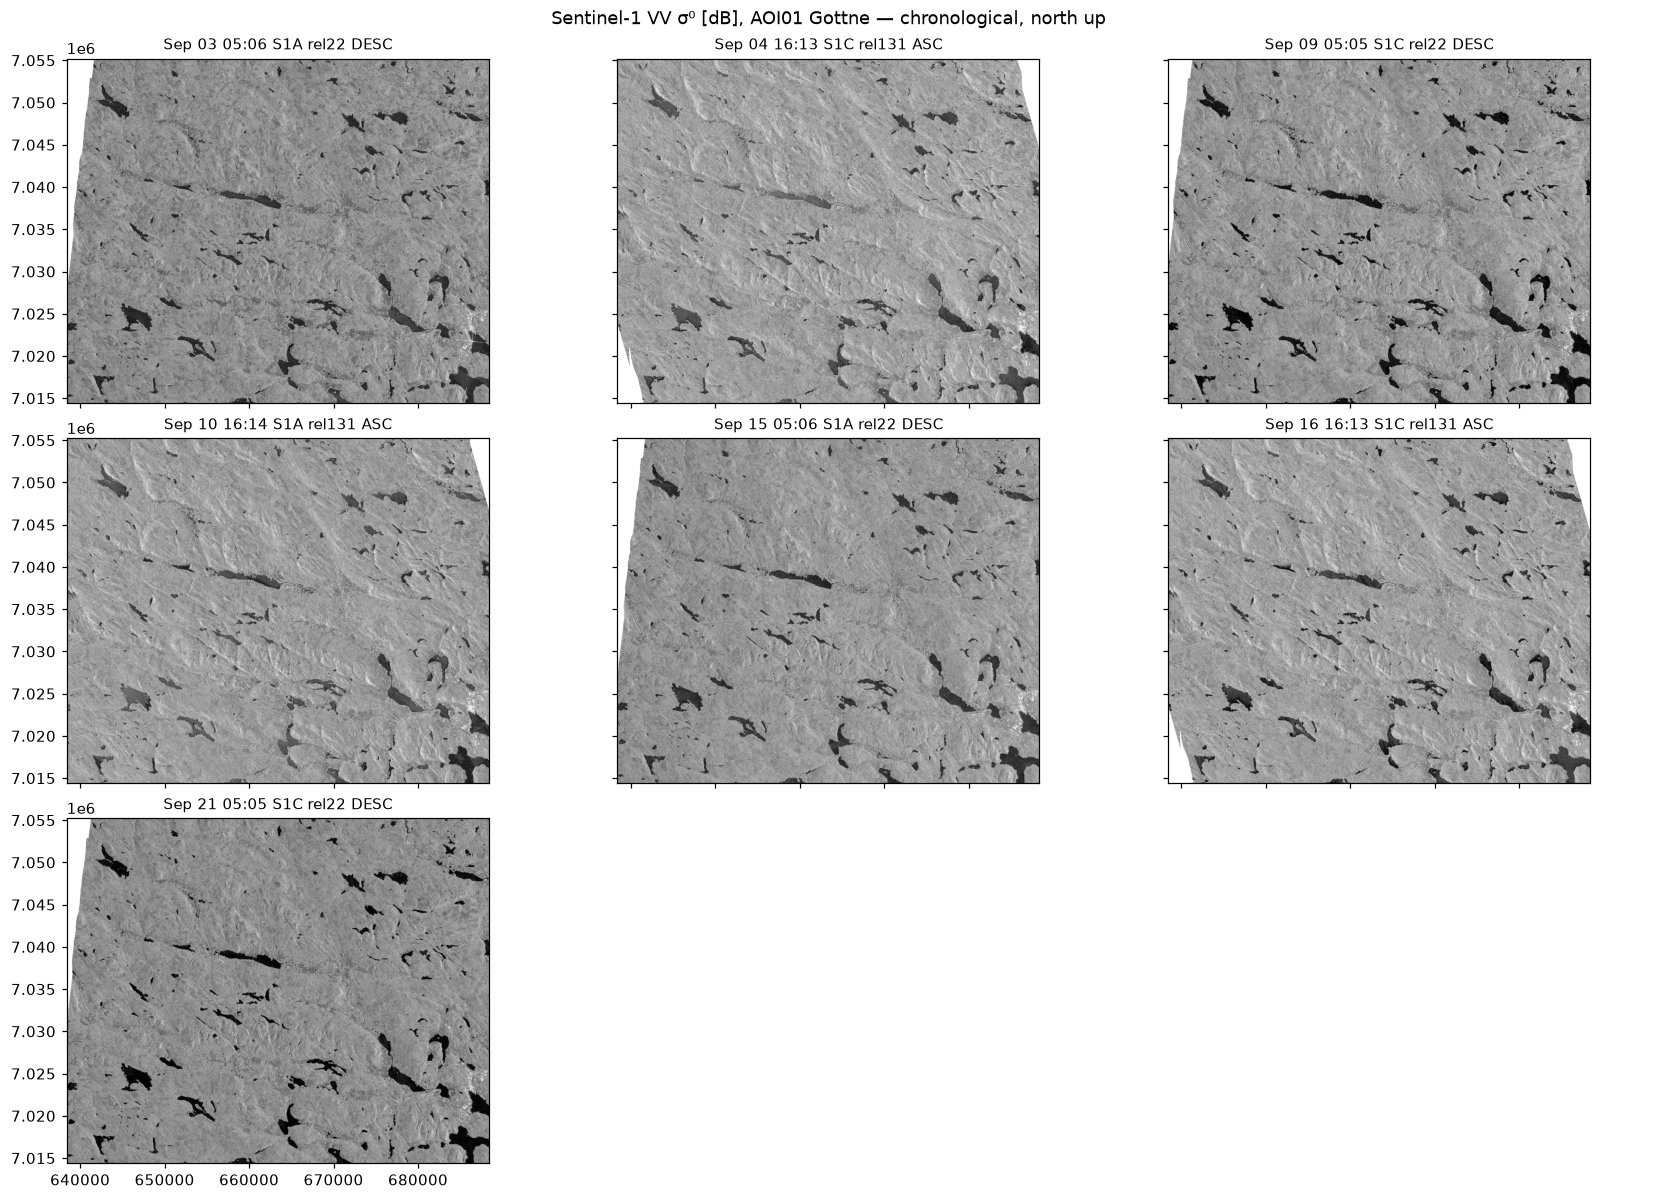

In [ ]:
keys = sorted(scenes, key=lambda k: scenes[k]["meta"].start)
n = len(keys)
ncols = 3
nrows = -(-n // ncols)
# explicit north-up extent, robust to either y ordering (sarsen writes south-to-north)
da0 = scenes[keys[0]]["da"]
yy = da0.y.values
IM_ORIGIN = "lower" if yy[0] < yy[-1] else "upper"
full_extent = [float(da0.x[0]), float(da0.x[-1]), float(min(yy[0], yy[-1])), float(max(yy[0], yy[-1]))]
# note: sharex/sharey + constrained layout + fixed aspect silently drops titles on
# non-first columns (matplotlib quirk) -> no sharing, blank inner tick labels manually
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6 * nrows), layout="constrained")
for i, (ax, k) in enumerate(zip(np.ravel(axes), keys)):
    db = flood.to_db(scenes[k]["da"])
    ax.imshow(db.values, cmap="gray", vmin=-25, vmax=0,
              extent=full_extent, origin=IM_ORIGIN, aspect="equal")
    ax.set_title(k, fontsize=10)
    ax.set_ylim(full_extent[2], full_extent[3])
    if i % ncols: ax.set_yticklabels([])
    if i // ncols < nrows - 1: ax.set_xticklabels([])
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
fig.suptitle("Sentinel-1 VV σ⁰ [dB], AOI01 Gottne — chronological, north up")

## EMS reference labels

Four labelled EMS products exist for AOI01 (AOI02 was never produced). `observedEventA`
is the flood delineation of each product; MONIT products add `maximumFloodExtentA`
(cumulative). FEP has **no** flood-extent layer beyond `observedEventA`.

In [ ]:
EMS_PRODUCTS = {
    "FEP (S1 Sept 10 16:14)":      ("EMSR841_AOI01_FEP_PRODUCT_v1",  "FEP_PRODUCT",  "2025-09-10T16:14"),
    "DEL (ICEYE Sept 11 23:06)":   ("EMSR841_AOI01_DEL_PRODUCT_v1",  "DEL_PRODUCT",  "2025-09-11T23:06"),
    "MONIT01 (CSG Sept 12 16:57)": ("EMSR841_AOI01_DEL_MONIT01_v1",  "DEL_MONIT01",  "2025-09-12T16:57"),
    "MONIT02 (S1 Sept 15 05:06)":  ("EMSR841_AOI01_DEL_MONIT02_v1",  "DEL_MONIT02",  "2025-09-15T05:06"),
}
template = scenes[keys[0]]["da"]
# analysis region = EMS AOI polygon (labels are defined here; also excludes open sea)
aoi_gdf = gpd.read_file(EMS_DIR / "EMSR841_AOI01_DEL_MONIT02_v1/EMSR841_AOI01_DEL_MONIT02_areaOfInterestA_v1.json")
aoi_mask = flood.rasterize_labels(aoi_gdf, template)
print(f"analysis region (EMS AOI polygon): {float(aoi_mask.sum()) * 4e-4:.0f} km²")

labels = {}
for title, (d, stem, t) in EMS_PRODUCTS.items():
    gdf = gpd.read_file(EMS_DIR / d / f"EMSR841_AOI01_{stem}_observedEventA_v1.json")
    labels[title] = {"mask": flood.rasterize_labels(gdf, template), "time": pd.Timestamp(t), "n_polys": len(gdf)}
    mfe = EMS_DIR / d / f"EMSR841_AOI01_{stem}_maximumFloodExtentA_v1.json"
    if mfe.exists():
        labels[title]["max_extent"] = flood.rasterize_labels(gpd.read_file(mfe), template)

# cumulative "flood happened here at some point" reference: union of every EMS flood layer
ems_union = None
for v in labels.values():
    for layer in (v["mask"], v.get("max_extent")):
        if layer is not None:
            ems_union = layer if ems_union is None else (ems_union | layer)

pd.DataFrame({t: {"n_polys": v["n_polys"], "area_km2": round(float(v["mask"].sum()) * 4e-4, 2),
                  "has_max_extent": "max_extent" in v} for t, v in labels.items()}).T

analysis region (EMS AOI polygon): 57 km²


,n_polys,area_km2,has_max_extent
FEP (S1 Sept 10 16:14),208,1.91,False
DEL (ICEYE Sept 11 23:06),397,0.66,False
MONIT01 (CSG Sept 12 16:57),105,0.55,True
MONIT02 (S1 Sept 15 05:06),7,0.05,True


## Water masks and scores against EMS

Per acquisition: single-image Otsu-thresholded dark-water mask (capped at −14 dB).
Where a same-track pre-event reference exists, the **log-ratio** mask is used instead —
that's the WP4 image-domain baseline. Each detection is scored against the EMS product
nearest in time, with the offset stated. A permanent-water estimate (dark in the
pre-event rel-131 reference) is removed from both sides so scores measure *flood*, not rivers/lakes.

In [ ]:
# permanent water proxy: dark surface in the pre-event reference scene (Sept 4),
# restricted to the AOI polygon
ref_key = next(k for k in keys if scenes[k]["meta"].start.strftime("%m%d") == "0904")
ref_db = flood.to_db(scenes[ref_key]["da"]).where(aoi_mask)
perm_water, thr_pw = flood.water_mask_single(ref_db)
print(f"permanent-water proxy from '{ref_key}': thr={thr_pw:.1f} dB, "
      f"area={float(perm_water.sum()) * 4e-4:.1f} km² of "
      f"{float(aoi_mask.sum()) * 4e-4:.0f} km² AOI")

permanent-water proxy from 'Sep 04 16:13 S1C rel131 ASC': thr=-14.0 dB, area=18.4 km² of 57 km² AOI


In [ ]:
def same_track_reference(meta, all_prods):
    '''Earliest pre-event GRD on the same relative orbit, if any (activates post-download).'''
    cands = [p for p in all_prods
             if p.relative_orbit == meta.relative_orbit and p.start < meta.start
             and p.start < pd.Timestamp(cfg["event"]["window_during"][0]).to_pydatetime()]
    return min(cands, key=lambda p: abs((meta.start - p.start).days)) if cands else None

rows = []
detections = {}
for k in keys:
    meta = scenes[k]["meta"]
    db = flood.to_db(scenes[k]["da"]).where(aoi_mask)
    ref = same_track_reference(meta, prods)
    if ref is not None:
        ref_da = grd.gtc_sigma0(ref, "VV", dem_path,
                                GTC_DIR / f"{ref.platform}_{ref.relative_orbit:03d}_{ref.start:%Y%m%d}_VV_sigma0.tif",
                                crop_bbox=BBOX)
        mask, thr = flood.water_mask_logratio(db, flood.to_db(ref_da).where(aoi_mask))
        method = f"log-ratio vs {ref.start:%b %d}"
    else:
        mask, thr = flood.water_mask_single(db)
        method = "single-image Otsu"
    mask = mask & ~perm_water
    detections[k] = mask
    valid = xr.apply_ufunc(np.isfinite, db) & aoi_mask
    t = pd.Timestamp(meta.start)
    nearest = min(labels, key=lambda L: abs(labels[L]["time"] - t))
    # truth = observedEvent ∪ maximumFloodExtent: MONIT products delineate almost no
    # standing water at their own timestamp (0.05 km² for MONIT02) but carry the
    # cumulative extent — score against everything the product asserts flooded.
    truth = labels[nearest]["mask"]
    if "max_extent" in labels[nearest]:
        truth = truth | labels[nearest]["max_extent"]
    truth = truth & ~perm_water
    m = flood.iou_f1(mask, truth, valid=valid)
    mu = flood.iou_f1(mask, ems_union & ~perm_water, valid=valid)
    rows.append({"scene": k, "method": method, "thr_dB": round(thr, 1),
                 "vs": nearest, "offset_h": round(abs((labels[nearest]["time"] - t).total_seconds()) / 3600, 1),
                 "IoU": round(m["iou"], 3), "F1": round(m["f1"], 3),
                 "IoU_union": round(mu["iou"], 3),
                 "pred_km2": round(m["pred_area_km2"], 1), "ems_km2": round(m["truth_area_km2"], 1)})
scores = pd.DataFrame(rows)
scores

,scene,method,thr_dB,vs,offset_h,IoU,F1,IoU_union,pred_km2,ems_km2
0,Sep 03 05:06 S1A rel22 DESC,single-image Otsu,-14.7,FEP (S1 Sept 10 16:14),179.1,0.048,0.092,0.057,9.3,1.4
1,Sep 04 16:13 S1C rel131 ASC,single-image Otsu,-14.0,FEP (S1 Sept 10 16:14),144.0,0.000,0.000,0.000,0.0,1.4
2,Sep 09 05:05 S1C rel22 DESC,log-ratio vs Sep 03,-3.0,FEP (S1 Sept 10 16:14),35.1,0.049,0.093,0.058,7.1,1.4
3,Sep 10 16:14 S1A rel131 ASC,log-ratio vs Sep 04,-3.0,FEP (S1 Sept 10 16:14),0.0,0.047,0.089,0.063,9.2,1.4
4,Sep 15 05:06 S1A rel22 DESC,log-ratio vs Sep 03,-3.0,MONIT02 (S1 Sept 15 05:06),0.0,0.026,0.051,0.047,4.7,0.8
5,Sep 16 16:13 S1C rel131 ASC,log-ratio vs Sep 04,-3.0,MONIT02 (S1 Sept 15 05:06),35.1,0.024,0.047,0.045,8.1,0.8
6,Sep 21 05:05 S1C rel22 DESC,log-ratio vs Sep 03,-3.0,MONIT02 (S1 Sept 15 05:06),144.0,0.013,0.025,0.033,8.1,0.8


The per-scene numbers above are the honest baseline. Expected pattern: the largest
detected areas and best agreement around Sept 8–10; IoU is limited both by the
label-to-acquisition offset (flood recedes between S1 pass and EMS source image)
and by single-image detection where no same-track reference exists yet.

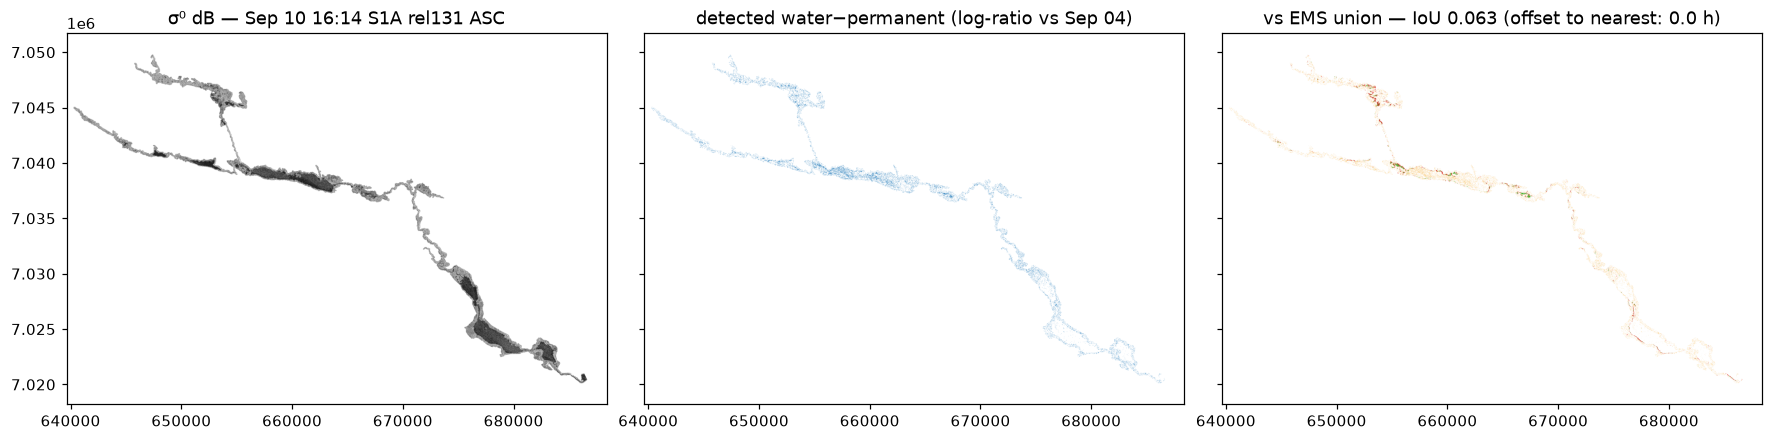

In [ ]:
# Visual: best-scoring scene vs its EMS reference (zoomed to the labelled valley)
best = scores.sort_values("IoU_union").iloc[-1]
k = best["scene"]
db = flood.to_db(scenes[k]["da"]).where(aoi_mask)
truth = (ems_union & ~perm_water)
pred = detections[k]

# zoom window = bounding box of EMS union labels + 2 km margin
ys, xs = np.where(np.asarray(ems_union))
y0, y1 = max(ys.min() - 100, 0), min(ys.max() + 100, ems_union.shape[0])
x0, x1 = max(xs.min() - 100, 0), min(xs.max() + 100, ems_union.shape[1])
sl = dict(y=slice(y0, y1), x=slice(x0, x1))

dbz = db.isel(**sl)
# explicit north-up extent, robust to either y ordering: left,right,bottom,top
yyz = dbz.y.values
extent = [float(dbz.x[0]), float(dbz.x[-1]), float(min(yyz[0], yyz[-1])), float(max(yyz[0], yyz[-1]))]
imargs = dict(extent=extent, origin="lower" if yyz[0] < yyz[-1] else "upper", aspect="equal")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), layout="constrained")
axes[0].imshow(dbz.values, cmap="gray", vmin=-25, vmax=0, **imargs)
axes[0].set_title(f"σ⁰ dB — {k}")
axes[1].imshow(np.where(pred.isel(**sl).values, 1.0, np.nan),
               cmap="Blues", vmin=0, vmax=1.5, **imargs)
axes[1].set_title(f"detected water−permanent ({best['method']})")
p = pred.isel(**sl).values; tr = truth.isel(**sl).values
overlay = np.zeros(p.shape + (4,))
overlay[p & tr] = (0, 0.7, 0, 0.9)     # green TP
overlay[p & ~tr] = (0.95, 0.6, 0, 0.5) # orange FP
overlay[~p & tr] = (0.85, 0, 0, 0.9)   # red FN
axes[2].imshow(overlay, **imargs)
axes[2].set_title(f"vs EMS union — IoU {best['IoU_union']} (offset to nearest: {best['offset_h']} h)")
for j, ax in enumerate(axes):
    ax.set_ylim(extent[2], extent[3])             # pin north up
    if j: ax.set_yticklabels([])

## Three zoomed hotspots — before / during / after

The plot above shows the whole labelled valley, but the actual flood is small enough
(≈2.6 km² total) that individual water bodies are hard to make out by eye at that
scale. Below: the **3 sub-areas where the detector found the most correctly-detected
flood** at the best-scoring scene (real, EMS-confirmed water, not false alarms), each
shown at three points in time on the *same track* — an early pre-event pass, the
best-scoring during-event pass, and a late post-event pass — so the same physical
ground can be watched actually flooding and draining. Same 3-panel layout as above,
one row per date; each row also states its own IoU, since the detection method
(single-image vs log-ratio) legitimately differs by scene.

rel131 track: before=Sep 04 16:13 S1C rel131 ASC | during=Sep 10 16:14 S1A rel131 ASC | after=Sep 16 16:13 S1C rel131 ASC
hotspot 1/3: ~1.2x1.2 km window, 255 true-positive px inside
hotspot 2/3: ~1.2x1.2 km window, 242 true-positive px inside
hotspot 3/3: ~1.2x1.2 km window, 190 true-positive px inside


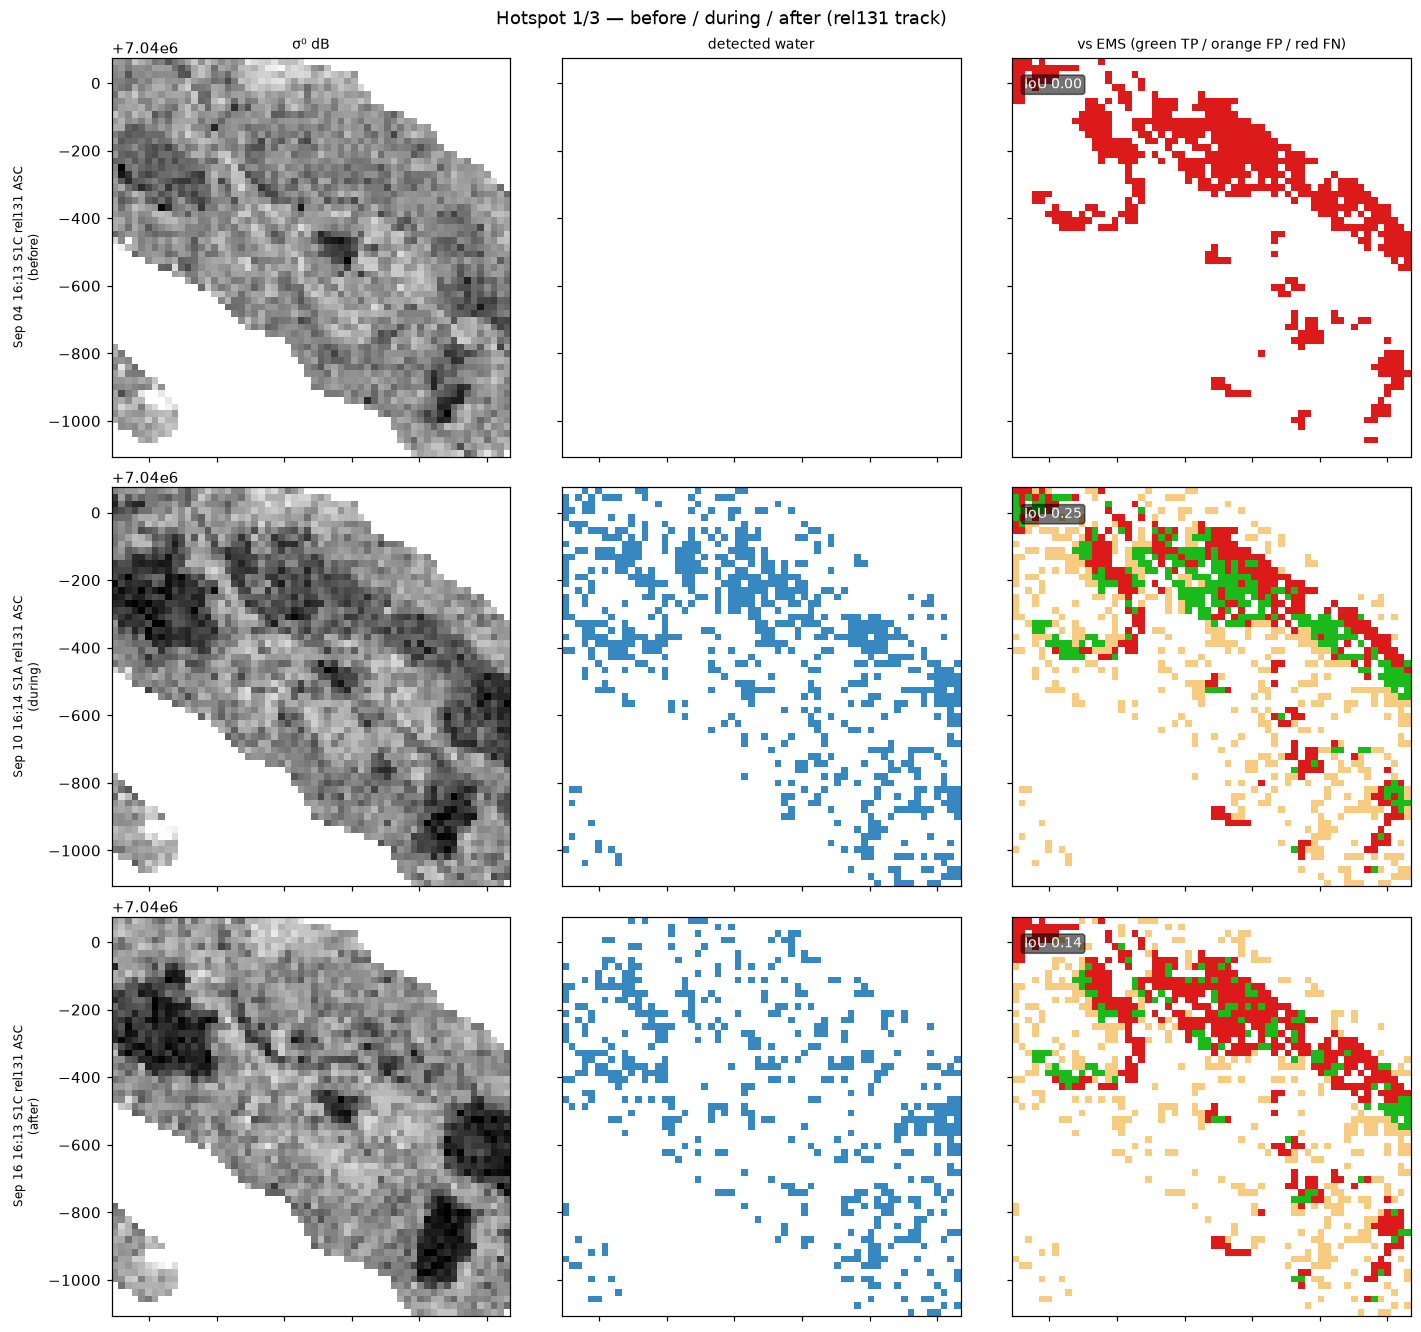

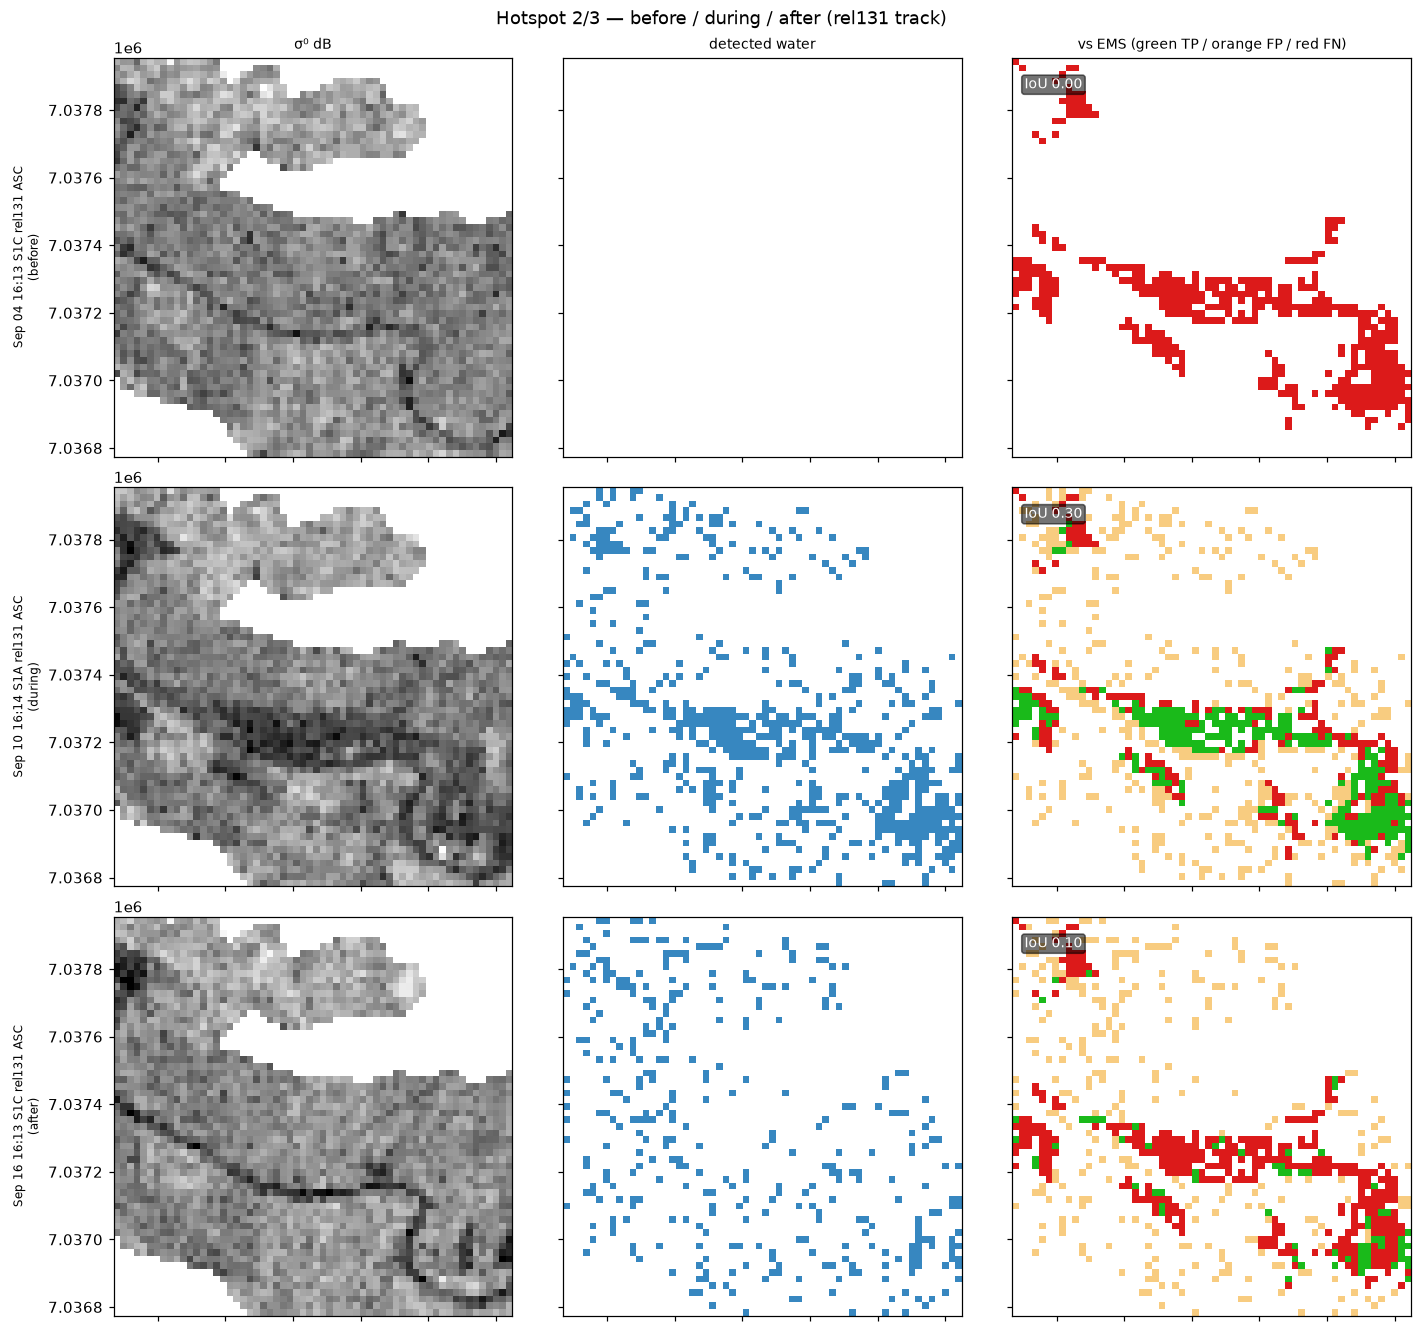

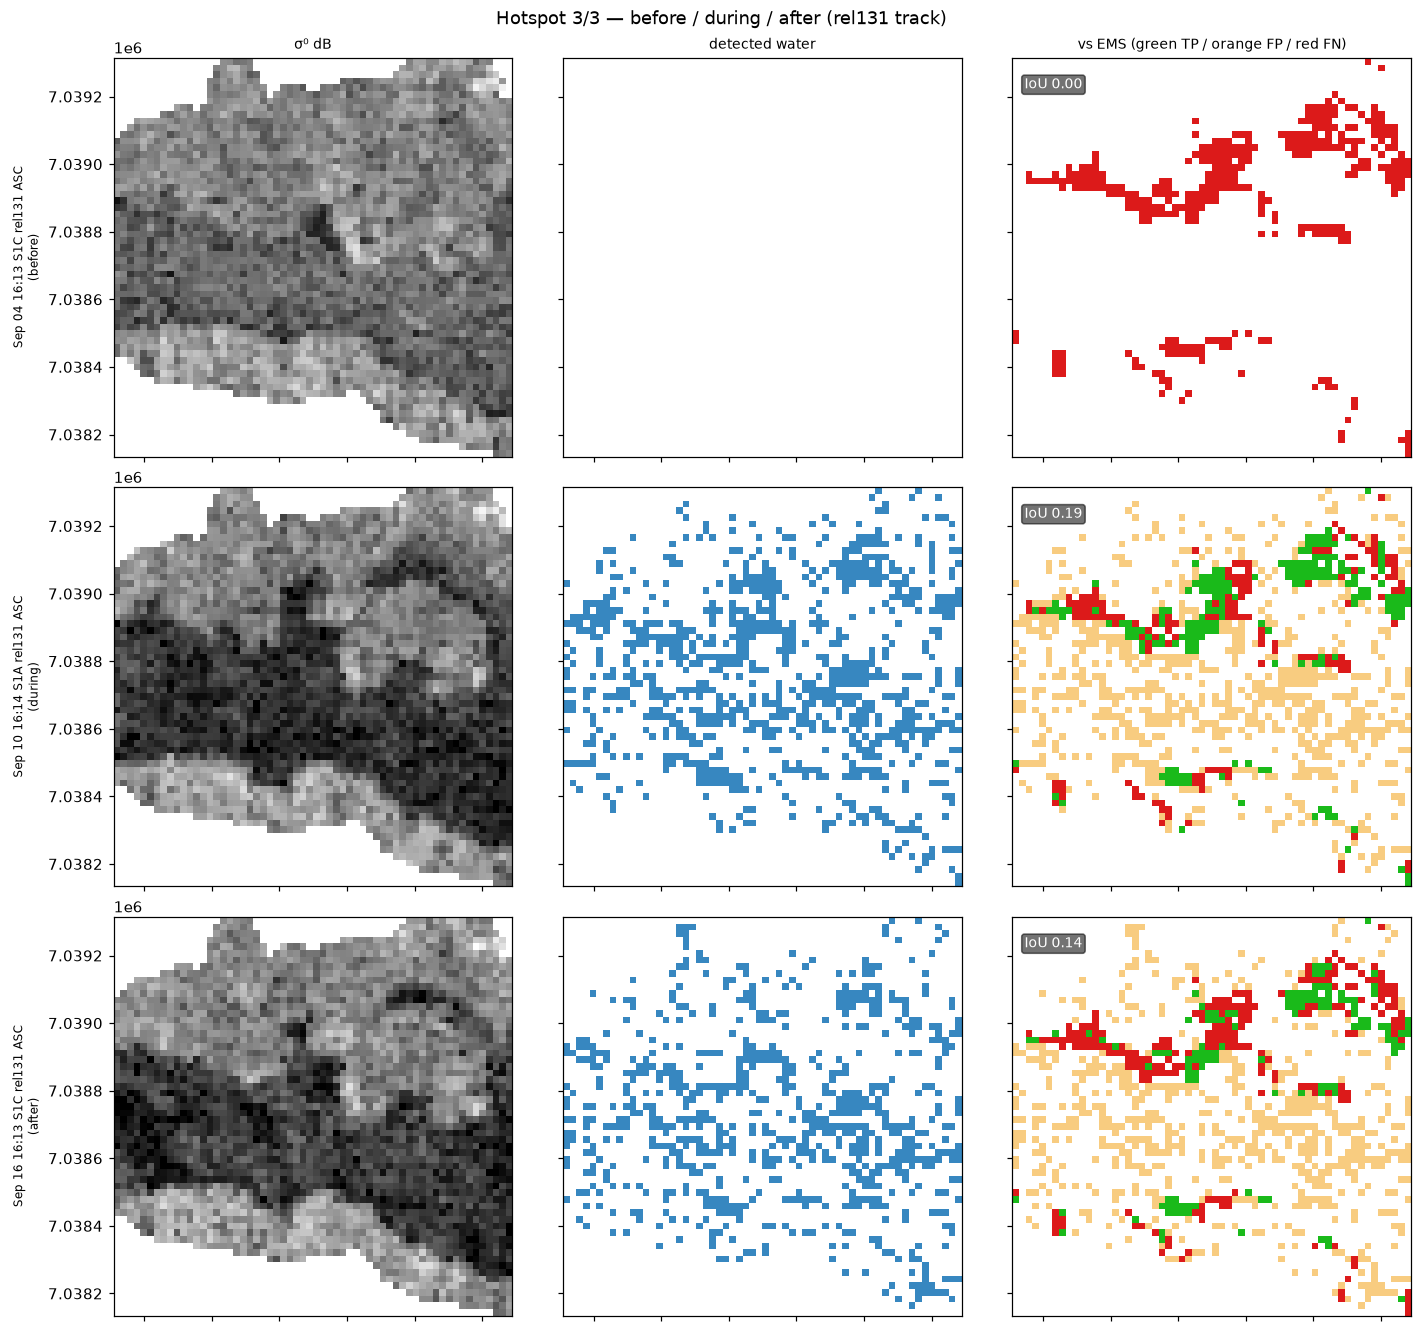

In [ ]:
# Three zoomed hotspots: most correctly-detected flood, before/during/after the
# same track (identical viewing geometry -> a fair "watch this spot" comparison).
best_meta = scenes[k]["meta"]
track_keys = sorted([kk for kk in keys if scenes[kk]["meta"].relative_orbit == best_meta.relative_orbit],
                     key=lambda kk: scenes[kk]["meta"].start)
before_k, during_k, after_k = track_keys[0], k, track_keys[-1]
print(f"rel{best_meta.relative_orbit} track: before={before_k} | during={during_k} | after={after_k}")

WIN = 60  # px, 20 m grid -> 1.2x1.2 km per hotspot
tp_full = np.asarray(pred) & np.asarray(truth)
windows = flood.top_hotspot_windows(tp_full, window=WIN, n=3)

for wi, (ysl, xsl) in enumerate(windows, 1):
    print(f"hotspot {wi}/3: ~{WIN * 0.02:.1f}x{WIN * 0.02:.1f} km window, "
          f"{int(tp_full[ysl, xsl].sum())} true-positive px inside")
    fig, axes = plt.subplots(3, 3, figsize=(13, 12), layout="constrained")
    for row, (tk, label) in enumerate([(before_k, "before"), (during_k, "during"), (after_k, "after")]):
        dbz = flood.to_db(scenes[tk]["da"]).where(aoi_mask).isel(y=ysl, x=xsl)
        predz = detections[tk].isel(y=ysl, x=xsl)
        truthz = truth.isel(y=ysl, x=xsl)
        yyz = dbz.y.values
        extent = [float(dbz.x[0]), float(dbz.x[-1]), float(min(yyz[0], yyz[-1])), float(max(yyz[0], yyz[-1]))]
        imargs = dict(extent=extent, origin="lower" if yyz[0] < yyz[-1] else "upper", aspect="equal")

        axes[row, 0].imshow(dbz.values, cmap="gray", vmin=-25, vmax=0, **imargs)
        axes[row, 1].imshow(np.where(predz.values, 1.0, np.nan), cmap="Blues", vmin=0, vmax=1.5, **imargs)
        p, tr = predz.values, truthz.values
        overlay = np.zeros(p.shape + (4,))
        overlay[p & tr] = (0, 0.7, 0, 0.9)     # green TP
        overlay[p & ~tr] = (0.95, 0.6, 0, 0.5) # orange FP
        overlay[~p & tr] = (0.85, 0, 0, 0.9)   # red FN
        axes[row, 2].imshow(overlay, **imargs)

        m = flood.iou_f1(predz, truthz)
        axes[row, 2].annotate(f"IoU {m['iou']:.2f}", xy=(0.03, 0.95), xycoords="axes fraction",
                               fontsize=9, color="white", va="top",
                               bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.55))
        axes[row, 0].set_ylabel(f"{tk}\n({label})", fontsize=8)
        for j in range(3):
            axes[row, j].set_ylim(extent[2], extent[3])
            axes[row, j].set_xticklabels([])
            if j: axes[row, j].set_yticklabels([])
    for j, t in enumerate(["σ⁰ dB", "detected water", "vs EMS (green TP / orange FP / red FN)"]):
        axes[0, j].set_title(t, fontsize=9)
    fig.suptitle(f"Hotspot {wi}/3 — before / during / after (rel{best_meta.relative_orbit} track)")
None

## Takeaways (final run of 2026-07-29, full manifest on disk)

- The σ⁰ → geocode → threshold pipeline runs end-to-end on all 11 scenes at
  ~50 s/scene (sarsen GTC, AOI-cropped, 20 m grid, peak ~6.6 GB RSS).
- The EMS AOI is a **57 km² valley corridor**; 18 km² of it is permanent water.
  The EMS flood labels are small: 1.9 km² (FEP, Sept 10) → 0.05 km² observed +
  1.06 km² cumulative max extent (MONIT02, Sept 15). MONIT products are scored
  against observedEvent ∪ maximumFloodExtent.
- **The zero-offset baseline numbers (this is what WP4 must beat):**
  log-ratio at the FEP anchor (Sept 10, offset 0 h) scores **IoU 0.047 / F1 0.089**;
  at the MONIT02 anchor (Sept 15) **IoU 0.026 / F1 0.051**. The failure mode is
  plain **over-detection**: ~9 km² of "new dark surface" against 1.4 km² of labelled
  flood — the capped −3 dB log-ratio threshold sweeps in wet fields, shadows and
  geometry noise. Time offset was the excuse before the downloads; it no longer is.
- A pre-event scene (Sept 3) "detects" 9.3 km² by single-image Otsu — a good
  null-test showing how much of the dark-surface signal is not flood. The log-ratio
  method correctly returns ~0 for the other pre-event scene (Sept 4 is its own
  reference epoch).
- These are deliberately untuned baselines (fixed caps, no despeckling, no slope
  mask, GLO-30 DEM). The point of the table is an honest floor with provenance,
  not a competitive flood mapper.

## Flood evolution in the labelled valley — Copernicus EMS labels on the raw GRD

Same zoom window as above, chronological, **no detection of our own** — each panel is
just the σ⁰ image (gray, water = dark) with the **Copernicus EMS flood polygons**
overlaid (red fill = union of all EMS flood layers; gold outline = the EMS AOI
corridor). The point is to see the official flood delineation against what the radar
actually measured on each date:

- **Sept 3–4 (pre-event)**: the red areas are still bright/gray in σ⁰ — dry land.
- **Sept 7–10 (rising water and peak — discharge crested Sept 10–11)**: the red areas
  turn dark — smooth open water where EMS later mapped the flood.
- **Sept 15–21 (recession)**: the red areas brighten again as water drains, leaving
  only the permanent river channel dark.

The panel title shows each scene's mean σ⁰ inside the EMS flood area — the single
number that tracks this darkening/brightening.

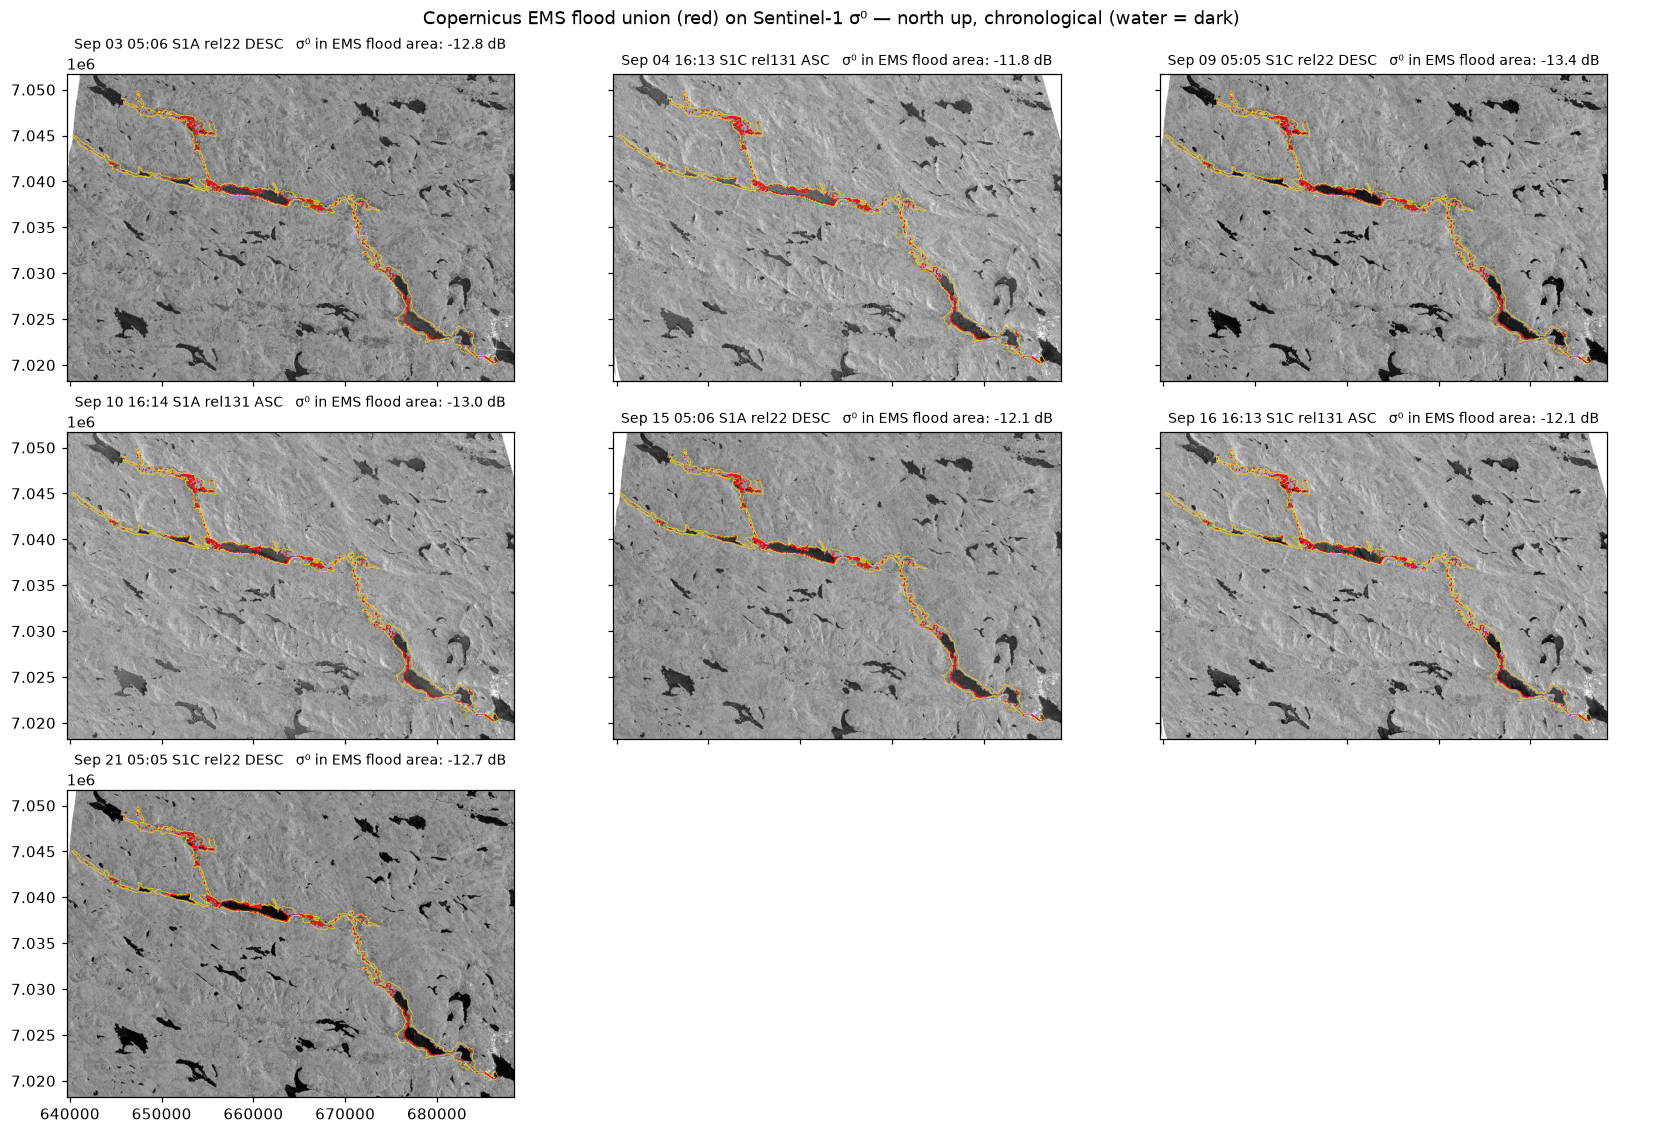

In [ ]:
# zoom window = bounding box of EMS union labels + 2 km margin (as in the figure above)
ys, xs = np.where(np.asarray(ems_union))
y0, y1 = max(ys.min() - 100, 0), min(ys.max() + 100, ems_union.shape[0])
x0, x1 = max(xs.min() - 100, 0), min(xs.max() + 100, ems_union.shape[1])
zoom = dict(y=slice(y0, y1), x=slice(x0, x1))
ems_zoom = np.asarray(ems_union.isel(**zoom))
aoi_zoom = np.asarray(aoi_mask.isel(**zoom))

# explicit north-up extent so the maps match a normal map view (Google-Maps-like:
# north up, west left); robust to either y ordering (sarsen writes south-to-north)
tmpl = scenes[keys[0]]["da"].isel(**zoom)
yyt = tmpl.y.values
extent = [float(tmpl.x[0]), float(tmpl.x[-1]), float(min(yyt[0], yyt[-1])), float(max(yyt[0], yyt[-1]))]
imargs = dict(extent=extent, origin="lower" if yyt[0] < yyt[-1] else "upper", aspect="equal")
xg, yg = tmpl.x.values, tmpl.y.values

ncols, nrows = 3, -(-len(keys) // 3)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.4 * nrows), layout="constrained")
ems_full = np.asarray(ems_union)  # for the per-scene mean-sigma0-in-flood-area number
for i, (ax, k) in enumerate(zip(np.ravel(axes), keys)):
    # background: sigma0 as measured (terrain context, not masked, no detection)
    db_full = flood.to_db(scenes[k]["da"])
    db = db_full.isel(**zoom)
    ax.imshow(db.values, cmap="gray", vmin=-25, vmax=0, **imargs)
    ax.contour(xg, yg, aoi_zoom, levels=[0.5], colors="gold", linewidths=0.5, alpha=0.8)
    fill = np.zeros(ems_zoom.shape + (4,))
    fill[ems_zoom.astype(bool)] = (0.9, 0.1, 0.1, 0.45)   # red: EMS flood union
    ax.imshow(fill, **imargs)
    ax.contour(xg, yg, ems_zoom, levels=[0.5], colors="red", linewidths=0.4, alpha=0.9)
    mean_db = float(db_full.values[ems_full.astype(bool)][np.isfinite(db_full.values[ems_full.astype(bool)])].mean())
    ax.set_title(f"{k}   σ⁰ in EMS flood area: {mean_db:.1f} dB", fontsize=9)
    ax.set_ylim(extent[2], extent[3])             # pin north up
    if i % ncols: ax.set_yticklabels([])
    if i // ncols < nrows - 1: ax.set_xticklabels([])
for ax in np.ravel(axes)[len(keys):]:
    ax.axis("off")
fig.suptitle("Copernicus EMS flood union (red) on Sentinel-1 σ⁰ — north up, chronological (water = dark)")
None

## When: the radar signal inside the EMS flood area, over time

No detection here either — one number per scene: the **mean σ⁰ (dB) inside the EMS
flood-union polygons**. Open water is radar-dark, so this curve dips exactly while
the area is inundated and recovers as it drains. Plotted against the river discharge
and the EMS label times. This is the "when"; the panel grid above is the "where".

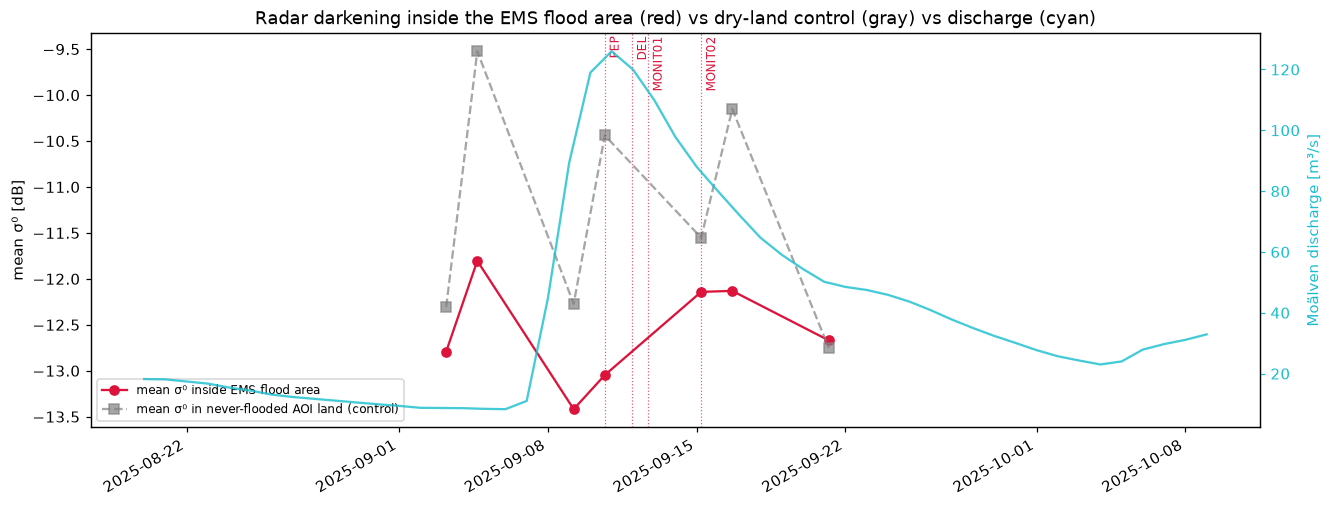

In [ ]:
t_scene = [pd.Timestamp(scenes[k]["meta"].start) for k in keys]
ems_bool = np.asarray(ems_union).astype(bool)
mean_db_flood, mean_db_dryref = [], []
dry_ref = np.asarray(aoi_mask).astype(bool) & ~ems_bool & ~np.asarray(perm_water).astype(bool)
for k in keys:
    v = flood.to_db(scenes[k]["da"]).values
    x = v[ems_bool];  mean_db_flood.append(float(x[np.isfinite(x)].mean()))
    x = v[dry_ref];   mean_db_dryref.append(float(x[np.isfinite(x)].mean()))

fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
ax.plot(t_scene, mean_db_flood, "o-", color="crimson", label="mean σ⁰ inside EMS flood area")
ax.plot(t_scene, mean_db_dryref, "s--", color="gray", alpha=0.7,
        label="mean σ⁰ in never-flooded AOI land (control)")
for title, v in labels.items():
    ax.axvline(v["time"], color="crimson", lw=0.8, ls=":", alpha=0.7)
    ax.annotate(title.split(" (")[0], (v["time"], ax.get_ylim()[1]), fontsize=8,
                color="crimson", rotation=90, va="top", xytext=(3, -2), textcoords="offset points")

# discharge on a secondary axis for the hydrological "when"
rows_q = [ln.split(";") for ln in
          (ROOT / "data/smhi/discharge_daily_1583_vastersel.csv").read_text().splitlines()
          if ln.startswith(("2025-08-2", "2025-08-3", "2025-09", "2025-10-0"))]
q = pd.Series({pd.Timestamp(p[0]): float(p[1]) for p in rows_q
               if len(p) > 1 and p[1].replace(".", "", 1).isdigit()})
ax2 = ax.twinx()
ax2.plot(q.index, q.values, color="tab:cyan", lw=1.5, alpha=0.8)
ax2.set_ylabel("Moälven discharge [m³/s]", color="tab:cyan")
ax2.tick_params(axis="y", colors="tab:cyan")

ax.set_ylabel("mean σ⁰ [dB]")
ax.set_title("Radar darkening inside the EMS flood area (red) vs dry-land control (gray) vs discharge (cyan)")
ax.legend(loc="lower left", fontsize=8)
fig.autofmt_xdate()
None

Read together: the red curve (radar signal where Copernicus mapped flood) drops by
several dB exactly as the discharge wave arrives and recovers through the recession,
while the gray control (never-flooded land in the same images) stays flat — so the
dip is water on the ground, not a scene-brightness or geometry artefact. Every
number here comes straight from the GRD pixels and the EMS polygons; no detection
algorithm of ours is involved.

## Trying smarter detection techniques

The baseline above is deliberately simple (single global Otsu cutoff, or log-ratio
against a pre-event reference) — its own Takeaways cell already names the gaps: no
despeckling, no slope mask. Below: three targeted improvements, each evaluated the
same way as the baseline (per-scene IoU/F1 table, best-scene visual, 3 zoomed
before/during/after hotspots), so any improvement is measured, not assumed. A shared
`evaluate_and_plot()` helper runs that whole evaluation once per technique instead of
repeating ~100 lines of scoring/plotting code three more times.

In [ ]:
def evaluate_and_plot(name, detect):
    '''Run detect(scene_key) -> (mask, thr, note) over every scene, score against EMS,
    print the table, draw the best-scene visual + 3 zoomed hotspots. Returns
    (scores_df, detections_dict) in the same shape as the baseline scores/detections.'''
    rows, dets = [], {}
    for kk in keys:
        meta = scenes[kk]["meta"]
        mask, thr, note = detect(kk)
        dets[kk] = mask
        db_kk = flood.to_db(scenes[kk]["da"]).where(aoi_mask)
        valid = np.isfinite(db_kk) & aoi_mask
        t = pd.Timestamp(meta.start)
        nearest = min(labels, key=lambda L: abs(labels[L]["time"] - t))
        tr = labels[nearest]["mask"]
        if "max_extent" in labels[nearest]:
            tr = tr | labels[nearest]["max_extent"]
        tr = tr & ~perm_water
        m = flood.iou_f1(mask, tr, valid=valid)
        mu = flood.iou_f1(mask, ems_union & ~perm_water, valid=valid)
        rows.append({"scene": kk, "method": note, "thr_dB": round(thr, 1),
                     "vs": nearest, "offset_h": round(abs((labels[nearest]["time"] - t).total_seconds()) / 3600, 1),
                     "IoU": round(m["iou"], 3), "F1": round(m["f1"], 3),
                     "IoU_union": round(mu["iou"], 3),
                     "pred_km2": round(m["pred_area_km2"], 1), "ems_km2": round(m["truth_area_km2"], 1)})
    df = pd.DataFrame(rows)
    print(f"=== {name} ===")
    display(df)

    best_row = df.sort_values("IoU_union").iloc[-1]
    bk = best_row["scene"]
    db_b = flood.to_db(scenes[bk]["da"]).where(aoi_mask)
    truth_b = ems_union & ~perm_water
    pred_b = dets[bk]
    ys, xs = np.where(np.asarray(ems_union))
    y0, y1 = max(ys.min() - 100, 0), min(ys.max() + 100, ems_union.shape[0])
    x0, x1 = max(xs.min() - 100, 0), min(xs.max() + 100, ems_union.shape[1])
    sl = dict(y=slice(y0, y1), x=slice(x0, x1))
    dbz = db_b.isel(**sl)
    yyz = dbz.y.values
    extent = [float(dbz.x[0]), float(dbz.x[-1]), float(min(yyz[0], yyz[-1])), float(max(yyz[0], yyz[-1]))]
    imargs = dict(extent=extent, origin="lower" if yyz[0] < yyz[-1] else "upper", aspect="equal")
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), layout="constrained")
    axes[0].imshow(dbz.values, cmap="gray", vmin=-25, vmax=0, **imargs)
    axes[0].set_title(f"σ⁰ dB — {bk}")
    axes[1].imshow(np.where(pred_b.isel(**sl).values, 1.0, np.nan), cmap="Blues", vmin=0, vmax=1.5, **imargs)
    axes[1].set_title(f"{name} detected water ({best_row['method']})")
    p = pred_b.isel(**sl).values; tr2 = truth_b.isel(**sl).values
    overlay = np.zeros(p.shape + (4,))
    overlay[p & tr2] = (0, 0.7, 0, 0.9)     # green TP
    overlay[p & ~tr2] = (0.95, 0.6, 0, 0.5) # orange FP
    overlay[~p & tr2] = (0.85, 0, 0, 0.9)   # red FN
    axes[2].imshow(overlay, **imargs)
    axes[2].set_title(f"vs EMS union — IoU {best_row['IoU_union']} (offset {best_row['offset_h']} h)")
    for j, ax in enumerate(axes):
        ax.set_ylim(extent[2], extent[3])
        if j: ax.set_yticklabels([])
    fig.suptitle(f"{name} — best-scoring scene")

    tp_full = np.asarray(pred_b) & np.asarray(truth_b)
    windows = flood.top_hotspot_windows(tp_full, window=WIN, n=3)
    track_keys2 = sorted([kk for kk in keys if scenes[kk]["meta"].relative_orbit == scenes[bk]["meta"].relative_orbit],
                          key=lambda kk: scenes[kk]["meta"].start)
    hb, hd, ha = track_keys2[0], bk, track_keys2[-1]
    for wi, (ysl, xsl) in enumerate(windows, 1):
        print(f"{name} hotspot {wi}/3: ~{WIN * 0.02:.1f}x{WIN * 0.02:.1f} km window, "
              f"{int(tp_full[ysl, xsl].sum())} true-positive px inside")
        fig, axes = plt.subplots(3, 3, figsize=(13, 12), layout="constrained")
        for row, (tk, lbl) in enumerate([(hb, "before"), (hd, "during"), (ha, "after")]):
            dbz2 = flood.to_db(scenes[tk]["da"]).where(aoi_mask).isel(y=ysl, x=xsl)
            predz = dets[tk].isel(y=ysl, x=xsl)
            truthz = truth_b.isel(y=ysl, x=xsl)
            yyz2 = dbz2.y.values
            extent2 = [float(dbz2.x[0]), float(dbz2.x[-1]), float(min(yyz2[0], yyz2[-1])), float(max(yyz2[0], yyz2[-1]))]
            imargs2 = dict(extent=extent2, origin="lower" if yyz2[0] < yyz2[-1] else "upper", aspect="equal")
            axes[row, 0].imshow(dbz2.values, cmap="gray", vmin=-25, vmax=0, **imargs2)
            axes[row, 1].imshow(np.where(predz.values, 1.0, np.nan), cmap="Blues", vmin=0, vmax=1.5, **imargs2)
            pz, trz = predz.values, truthz.values
            ov = np.zeros(pz.shape + (4,))
            ov[pz & trz] = (0, 0.7, 0, 0.9)
            ov[pz & ~trz] = (0.95, 0.6, 0, 0.5)
            ov[~pz & trz] = (0.85, 0, 0, 0.9)
            axes[row, 2].imshow(ov, **imargs2)
            mrow = flood.iou_f1(predz, truthz)
            axes[row, 2].annotate(f"IoU {mrow['iou']:.2f}", xy=(0.03, 0.95), xycoords="axes fraction",
                                   fontsize=9, color="white", va="top",
                                   bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.55))
            axes[row, 0].set_ylabel(f"{tk}\n({lbl})", fontsize=8)
            for j in range(3):
                axes[row, j].set_ylim(extent2[2], extent2[3])
                axes[row, j].set_xticklabels([])
                if j: axes[row, j].set_yticklabels([])
        for j, t in enumerate(["σ⁰ dB", "detected water", "vs EMS (green TP / orange FP / red FN)"]):
            axes[0, j].set_title(t, fontsize=9)
        fig.suptitle(f"{name} — hotspot {wi}/3 (rel{scenes[bk]['meta'].relative_orbit} track)")
    return df, dets

### 1. Despeckle

SAR images are inherently speckled — random constructive/destructive interference
that makes even a uniform surface look noisy pixel-to-pixel. A single noisy dark
pixel can trip a threshold even on dry land, and a single noisy bright pixel inside
real water can escape one. A median filter smooths that out *before* thresholding,
using the exact same Otsu/log-ratio decision logic as the baseline otherwise.

=== despeckle ===


,scene,method,thr_dB,vs,offset_h,IoU,F1,IoU_union,pred_km2,ems_km2
0,Sep 03 05:06 S1A rel22 DESC,despeckle+single-image Otsu,-15.0,FEP (S1 Sept 10 16:14),179.1,0.019,0.036,0.021,19.5,1.4
1,Sep 04 16:13 S1C rel131 ASC,despeckle+single-image Otsu,-14.0,FEP (S1 Sept 10 16:14),144.0,0.003,0.006,0.004,16.3,1.4
2,Sep 09 05:05 S1C rel22 DESC,despeckle+log-ratio vs Sep 03,-3.0,FEP (S1 Sept 10 16:14),35.1,0.023,0.044,0.026,10.9,1.4
3,Sep 10 16:14 S1A rel131 ASC,despeckle+log-ratio vs Sep 04,-3.0,FEP (S1 Sept 10 16:14),0.0,0.036,0.070,0.049,7.3,1.4
4,Sep 15 05:06 S1A rel22 DESC,despeckle+log-ratio vs Sep 03,-3.0,MONIT02 (S1 Sept 15 05:06),0.0,0.025,0.049,0.036,2.3,0.8
5,Sep 16 16:13 S1C rel131 ASC,despeckle+log-ratio vs Sep 04,-3.0,MONIT02 (S1 Sept 15 05:06),35.1,0.010,0.021,0.016,9.8,0.8
6,Sep 21 05:05 S1C rel22 DESC,despeckle+log-ratio vs Sep 03,-3.0,MONIT02 (S1 Sept 15 05:06),144.0,0.003,0.005,0.008,14.6,0.8


despeckle hotspot 1/3: ~1.2x1.2 km window, 239 true-positive px inside
despeckle hotspot 2/3: ~1.2x1.2 km window, 217 true-positive px inside
despeckle hotspot 3/3: ~1.2x1.2 km window, 169 true-positive px inside


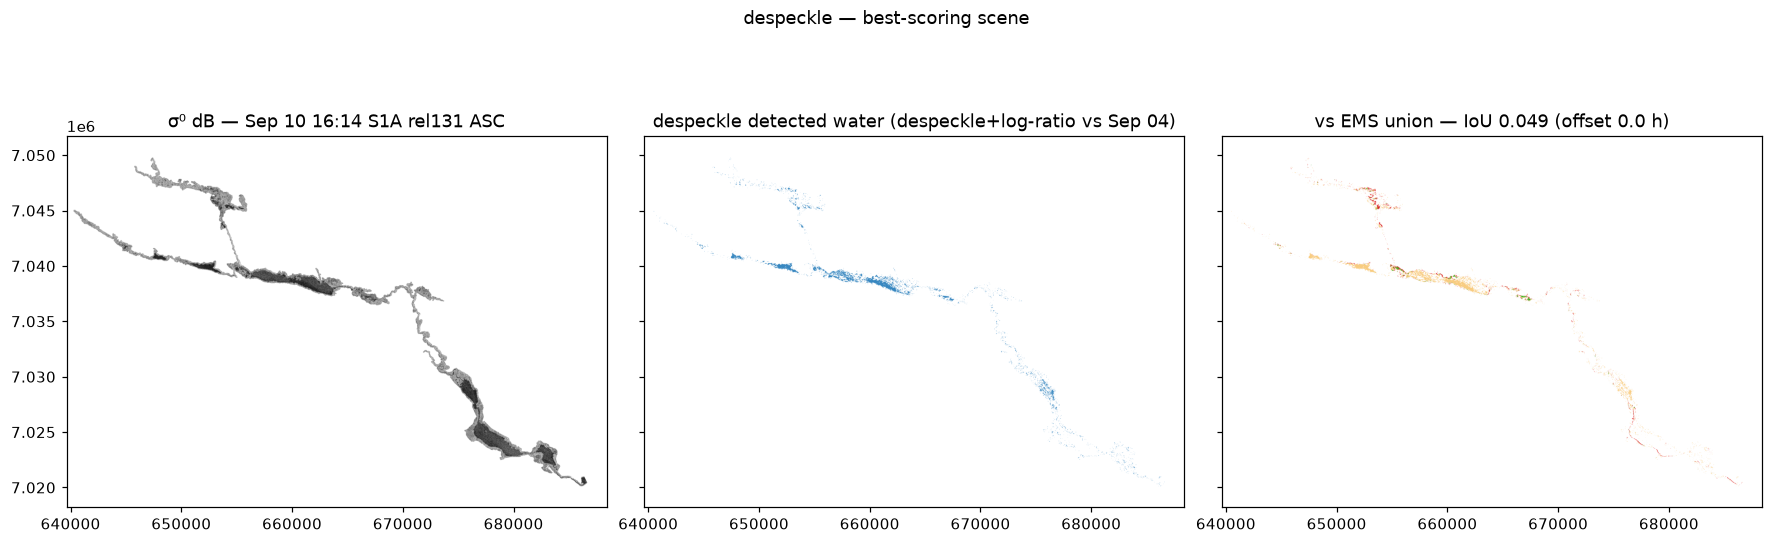

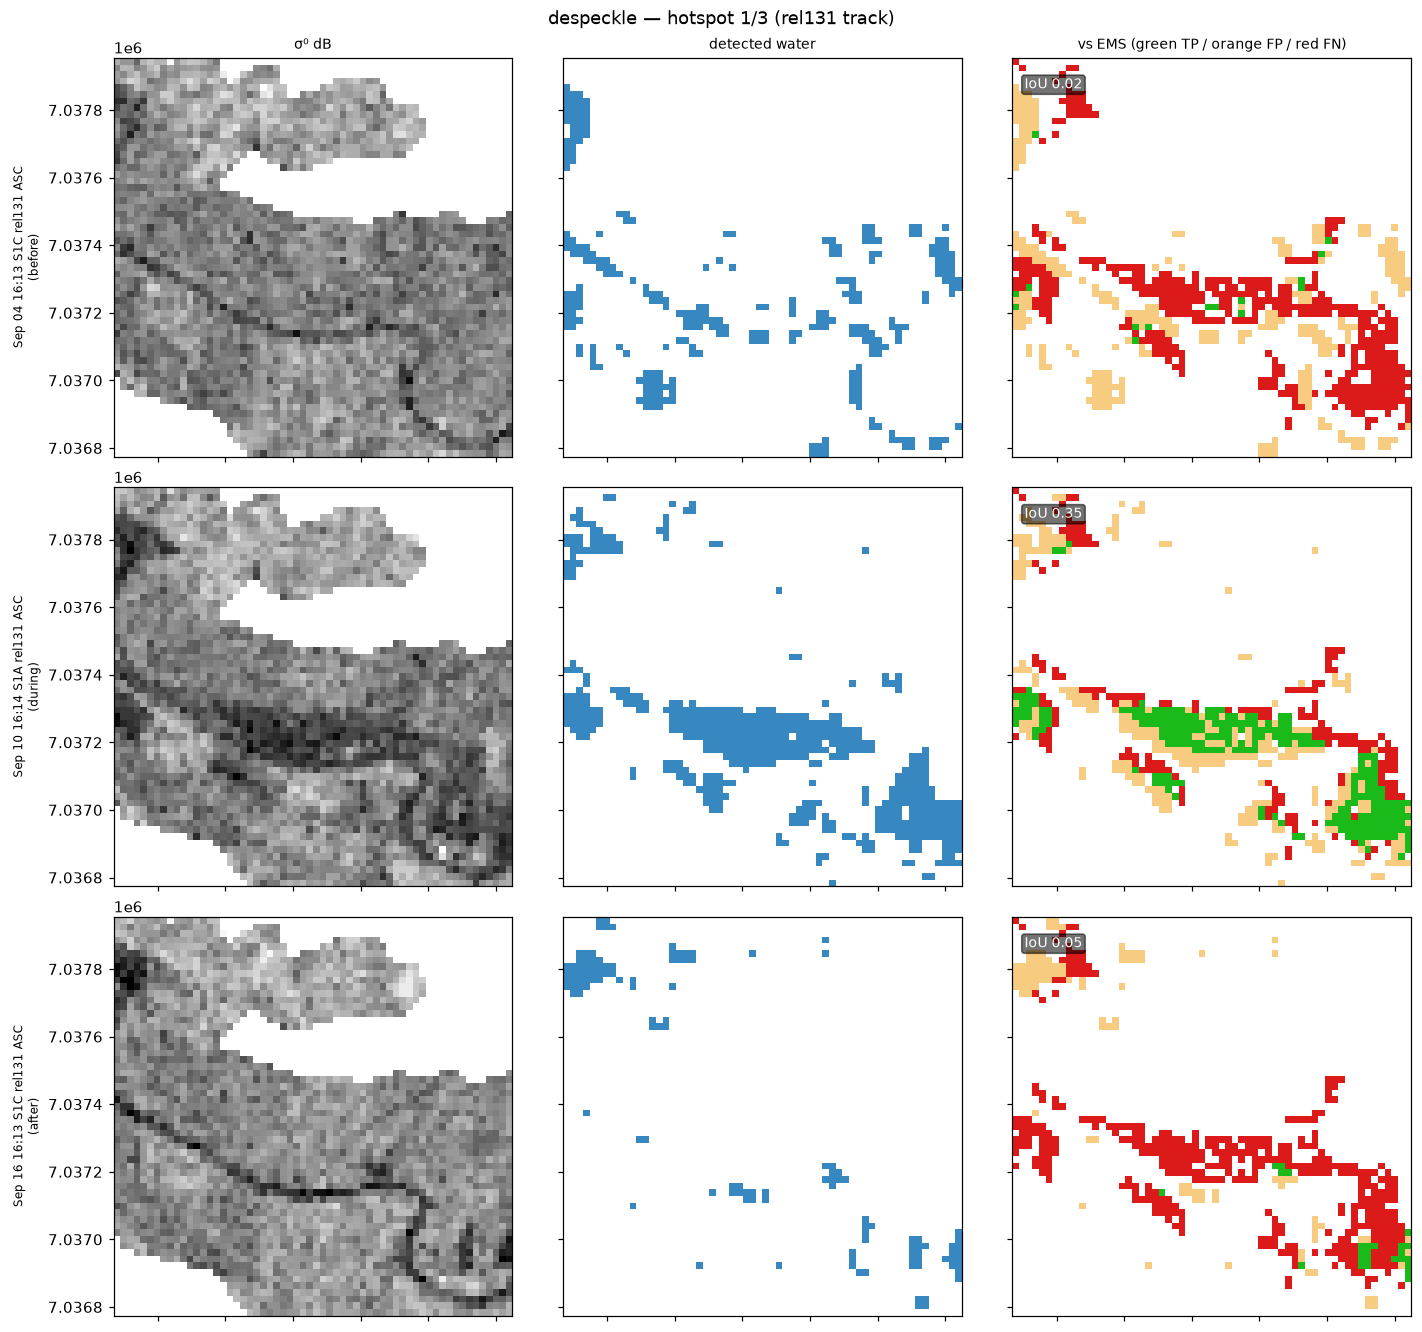

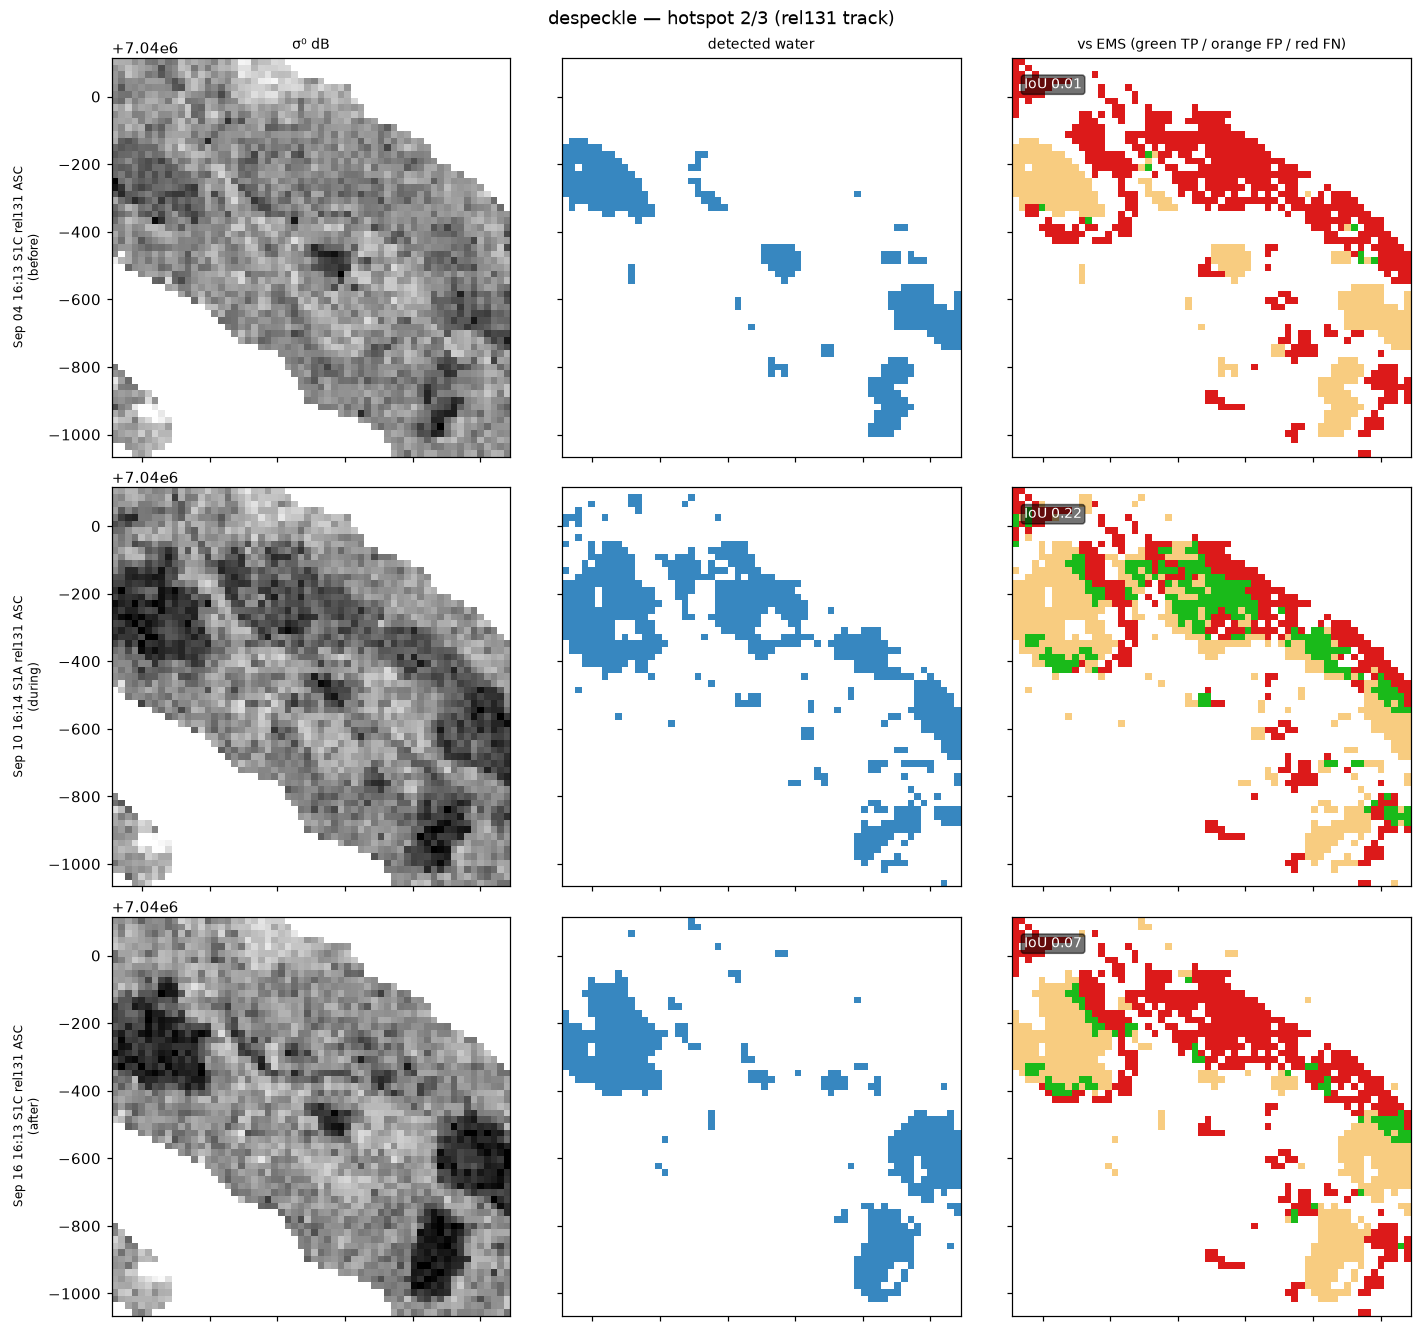

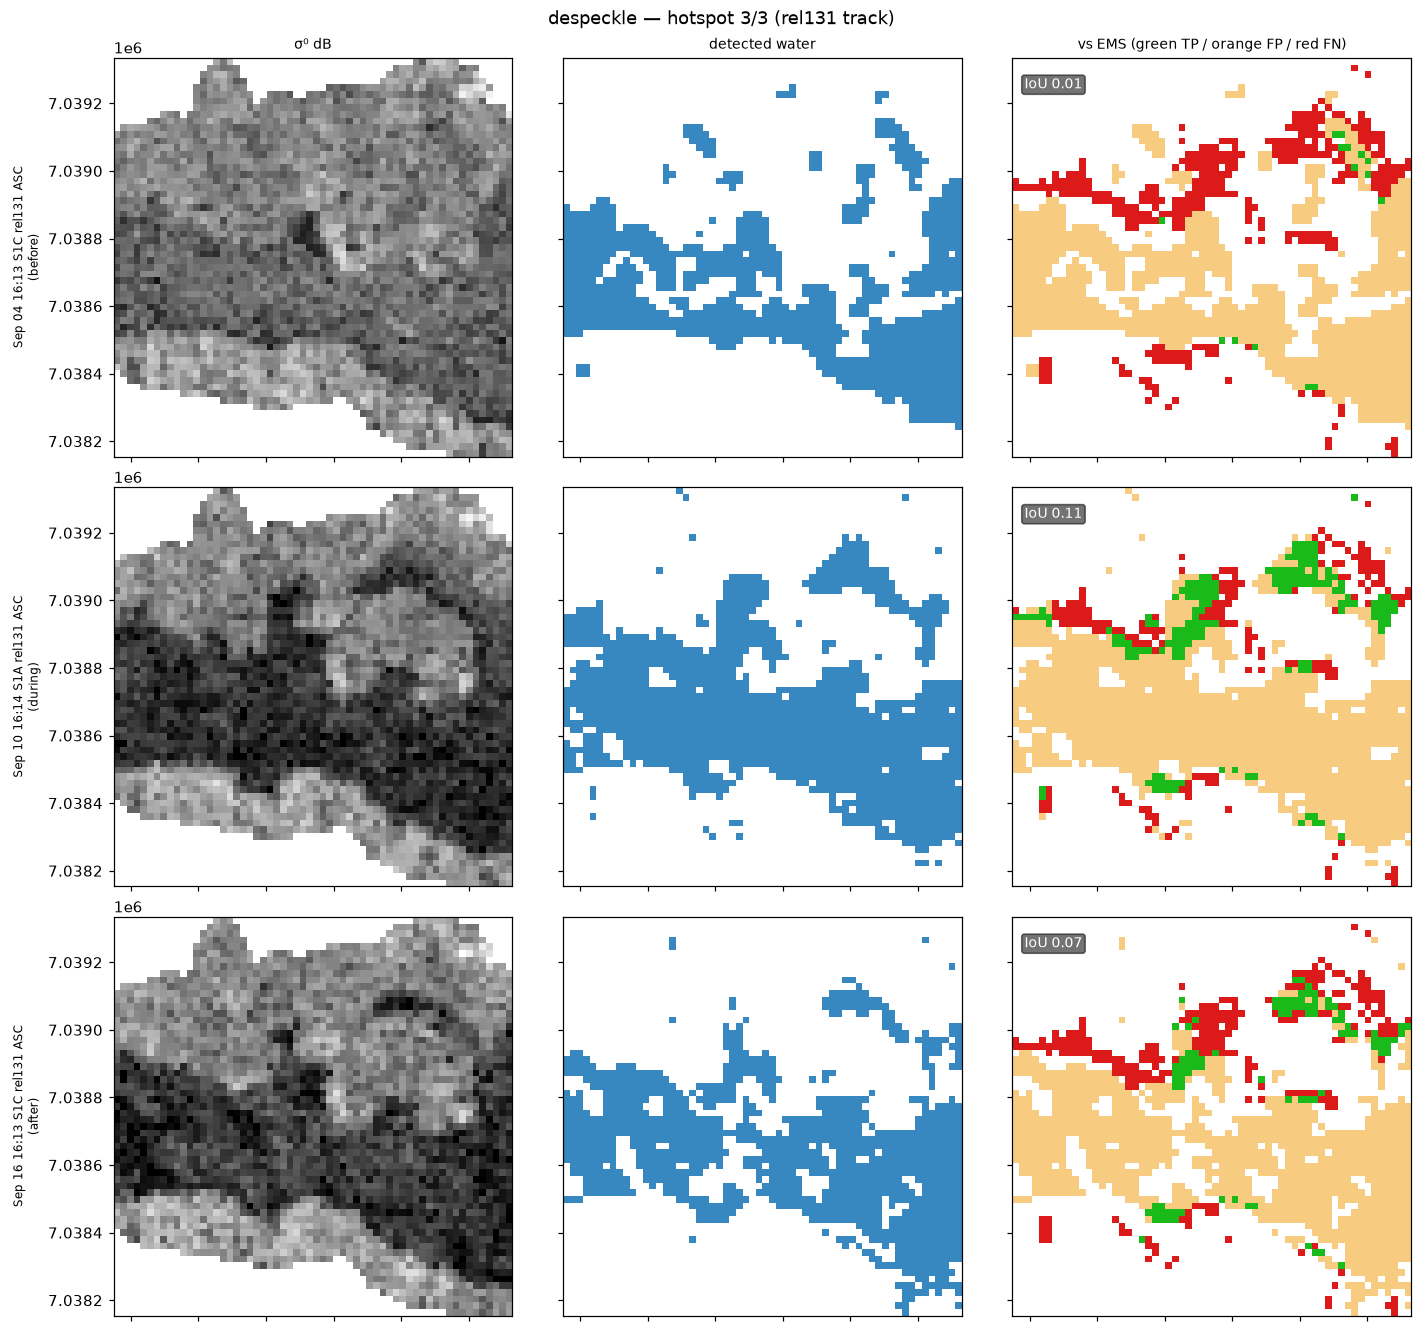

In [ ]:
def detect_despeckle(kk):
    meta = scenes[kk]["meta"]
    db = flood.despeckle(flood.to_db(scenes[kk]["da"]).where(aoi_mask))
    ref = same_track_reference(meta, prods)
    if ref is not None:
        ref_da = grd.gtc_sigma0(ref, "VV", dem_path,
                                GTC_DIR / f"{ref.platform}_{ref.relative_orbit:03d}_{ref.start:%Y%m%d}_VV_sigma0.tif",
                                crop_bbox=BBOX)
        ref_db = flood.despeckle(flood.to_db(ref_da).where(aoi_mask))
        mask, thr = flood.water_mask_logratio(db, ref_db)
        note = f"despeckle+log-ratio vs {ref.start:%b %d}"
    else:
        mask, thr = flood.water_mask_single(db)
        note = "despeckle+single-image Otsu"
    return mask, thr, note

scores_despeckle, dets_despeckle = evaluate_and_plot("despeckle", detect_despeckle)

### 2. Slope-mask

Water doesn't sit on a hillside — but steep terrain can still look radar-dark
(layover/shadow geometry, not water), a known false-positive source for a plain
brightness threshold. This builds on the despeckled detector above and removes any
"water" pixel sitting on a slope steeper than 5°, using the GLO-30 DEM already
downloaded for geocoding.

flat-terrain (<5°) fraction of AOI: 0.70
=== slope-mask ===


,scene,method,thr_dB,vs,offset_h,IoU,F1,IoU_union,pred_km2,ems_km2
0,Sep 03 05:06 S1A rel22 DESC,despeckle+single-image Otsu + slope<5°,-15.0,FEP (S1 Sept 10 16:14),179.1,0.016,0.032,0.019,18.5,1.4
1,Sep 04 16:13 S1C rel131 ASC,despeckle+single-image Otsu + slope<5°,-14.0,FEP (S1 Sept 10 16:14),144.0,0.002,0.005,0.003,15.4,1.4
2,Sep 09 05:05 S1C rel22 DESC,despeckle+log-ratio vs Sep 03 + slope<5°,-3.0,FEP (S1 Sept 10 16:14),35.1,0.019,0.038,0.022,10.1,1.4
3,Sep 10 16:14 S1A rel131 ASC,despeckle+log-ratio vs Sep 04 + slope<5°,-3.0,FEP (S1 Sept 10 16:14),0.0,0.037,0.071,0.047,6.2,1.4
4,Sep 15 05:06 S1A rel22 DESC,despeckle+log-ratio vs Sep 03 + slope<5°,-3.0,MONIT02 (S1 Sept 15 05:06),0.0,0.022,0.043,0.029,1.9,0.8
5,Sep 16 16:13 S1C rel131 ASC,despeckle+log-ratio vs Sep 04 + slope<5°,-3.0,MONIT02 (S1 Sept 15 05:06),35.1,0.008,0.015,0.012,8.9,0.8
6,Sep 21 05:05 S1C rel22 DESC,despeckle+log-ratio vs Sep 03 + slope<5°,-3.0,MONIT02 (S1 Sept 15 05:06),144.0,0.002,0.003,0.005,13.6,0.8


slope-mask hotspot 1/3: ~1.2x1.2 km window, 239 true-positive px inside
slope-mask hotspot 2/3: ~1.2x1.2 km window, 213 true-positive px inside
slope-mask hotspot 3/3: ~1.2x1.2 km window, 151 true-positive px inside


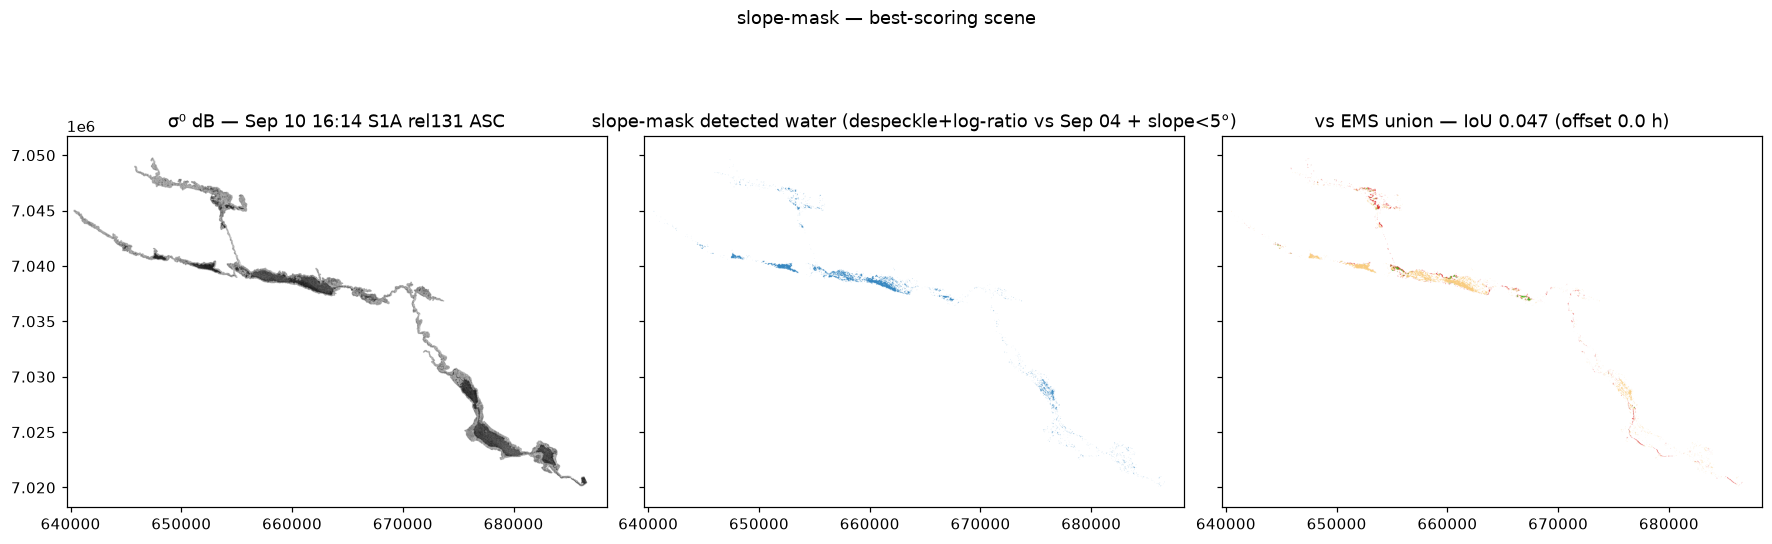

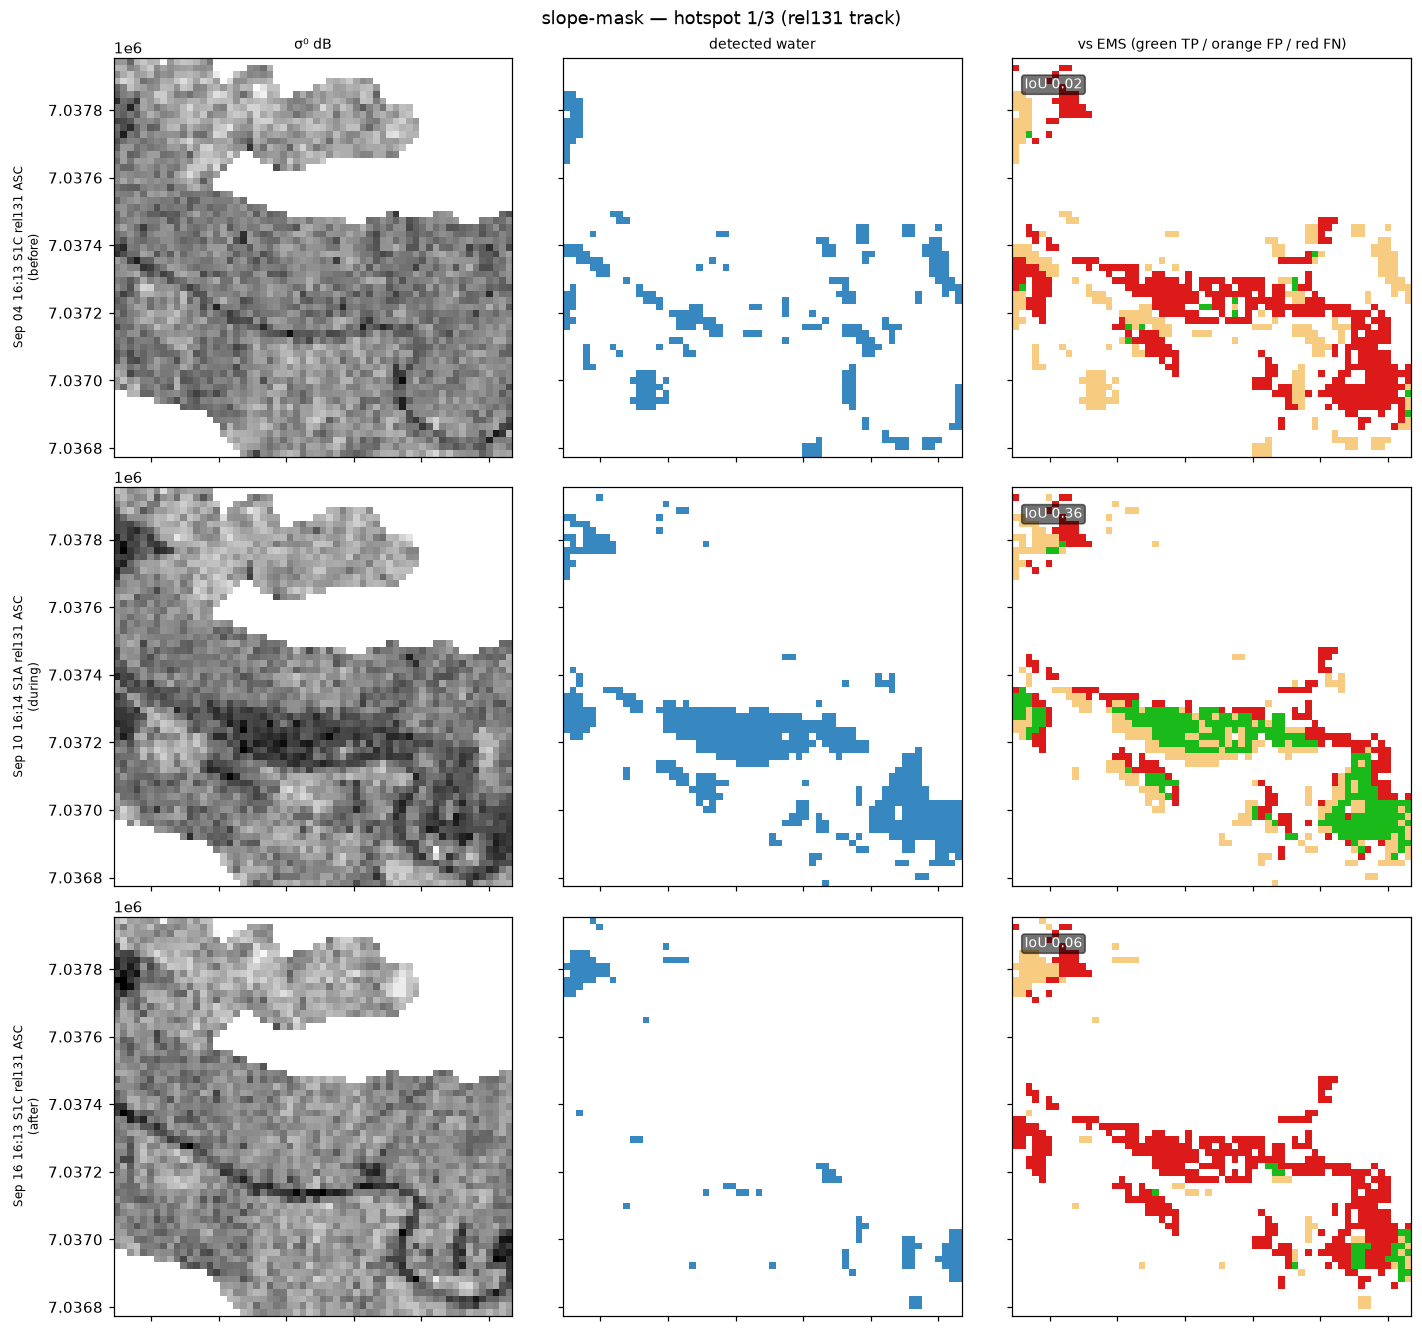

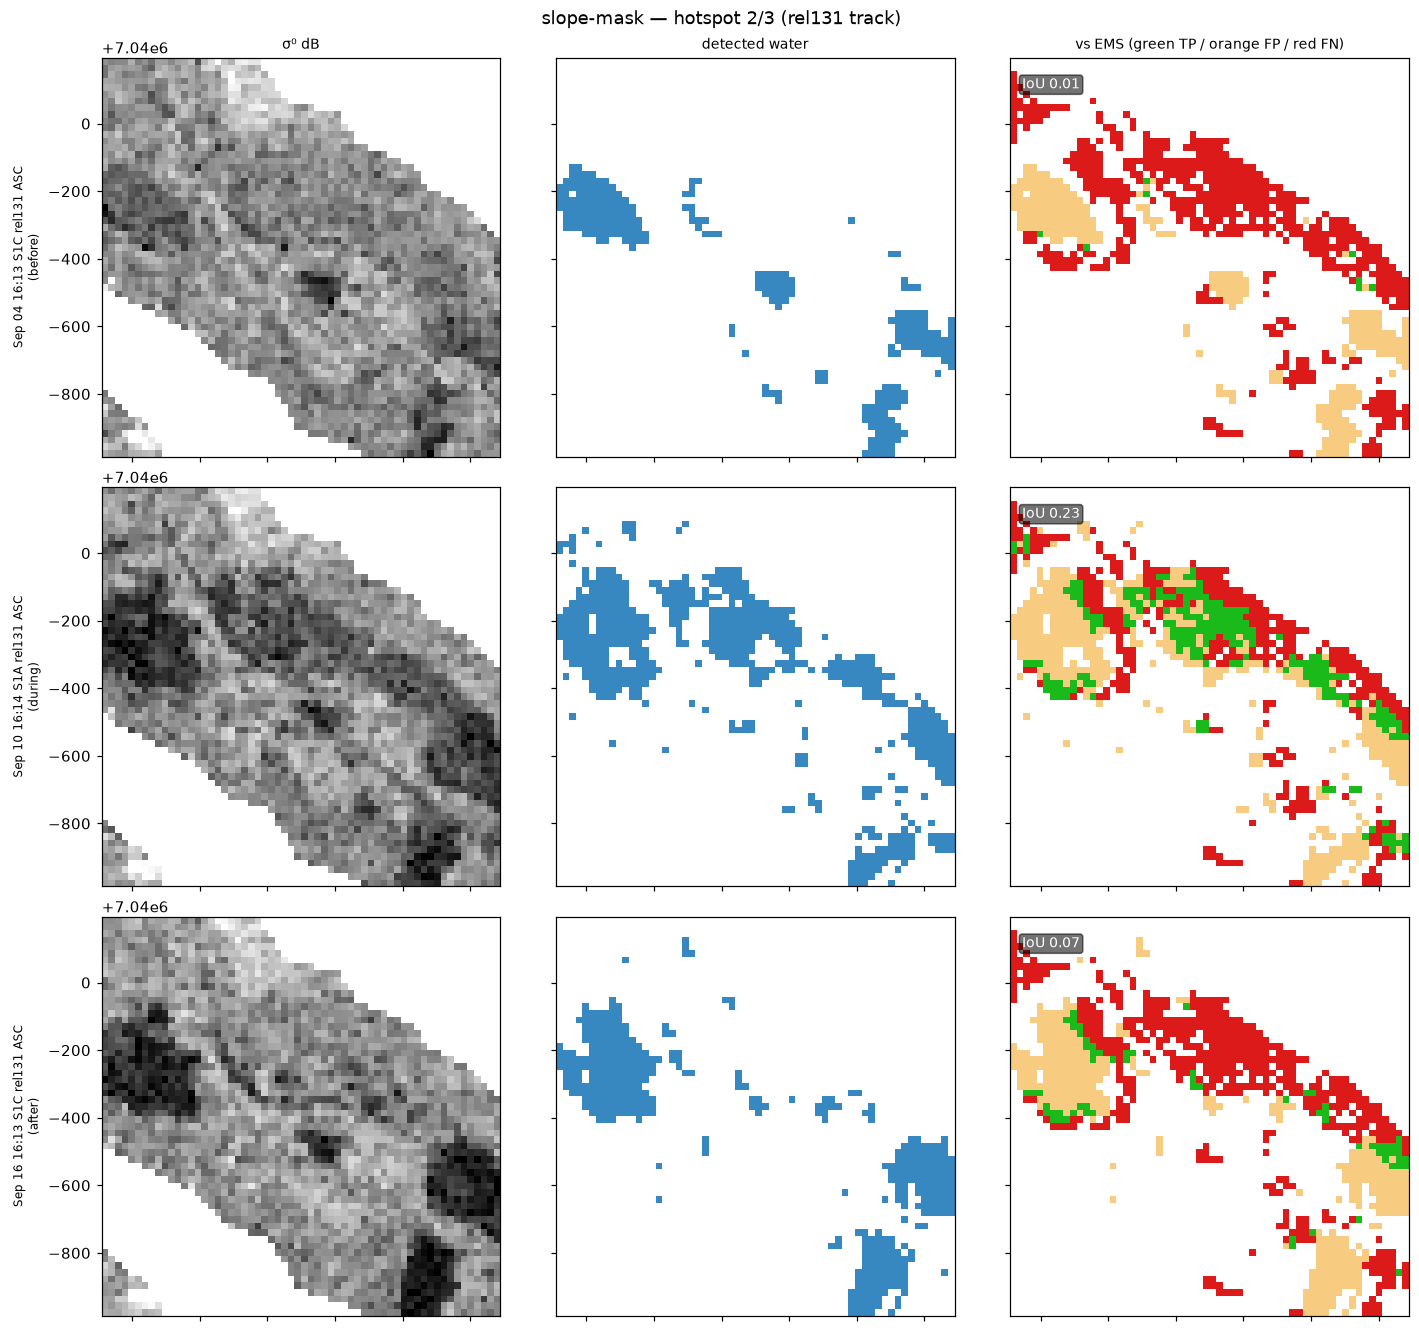

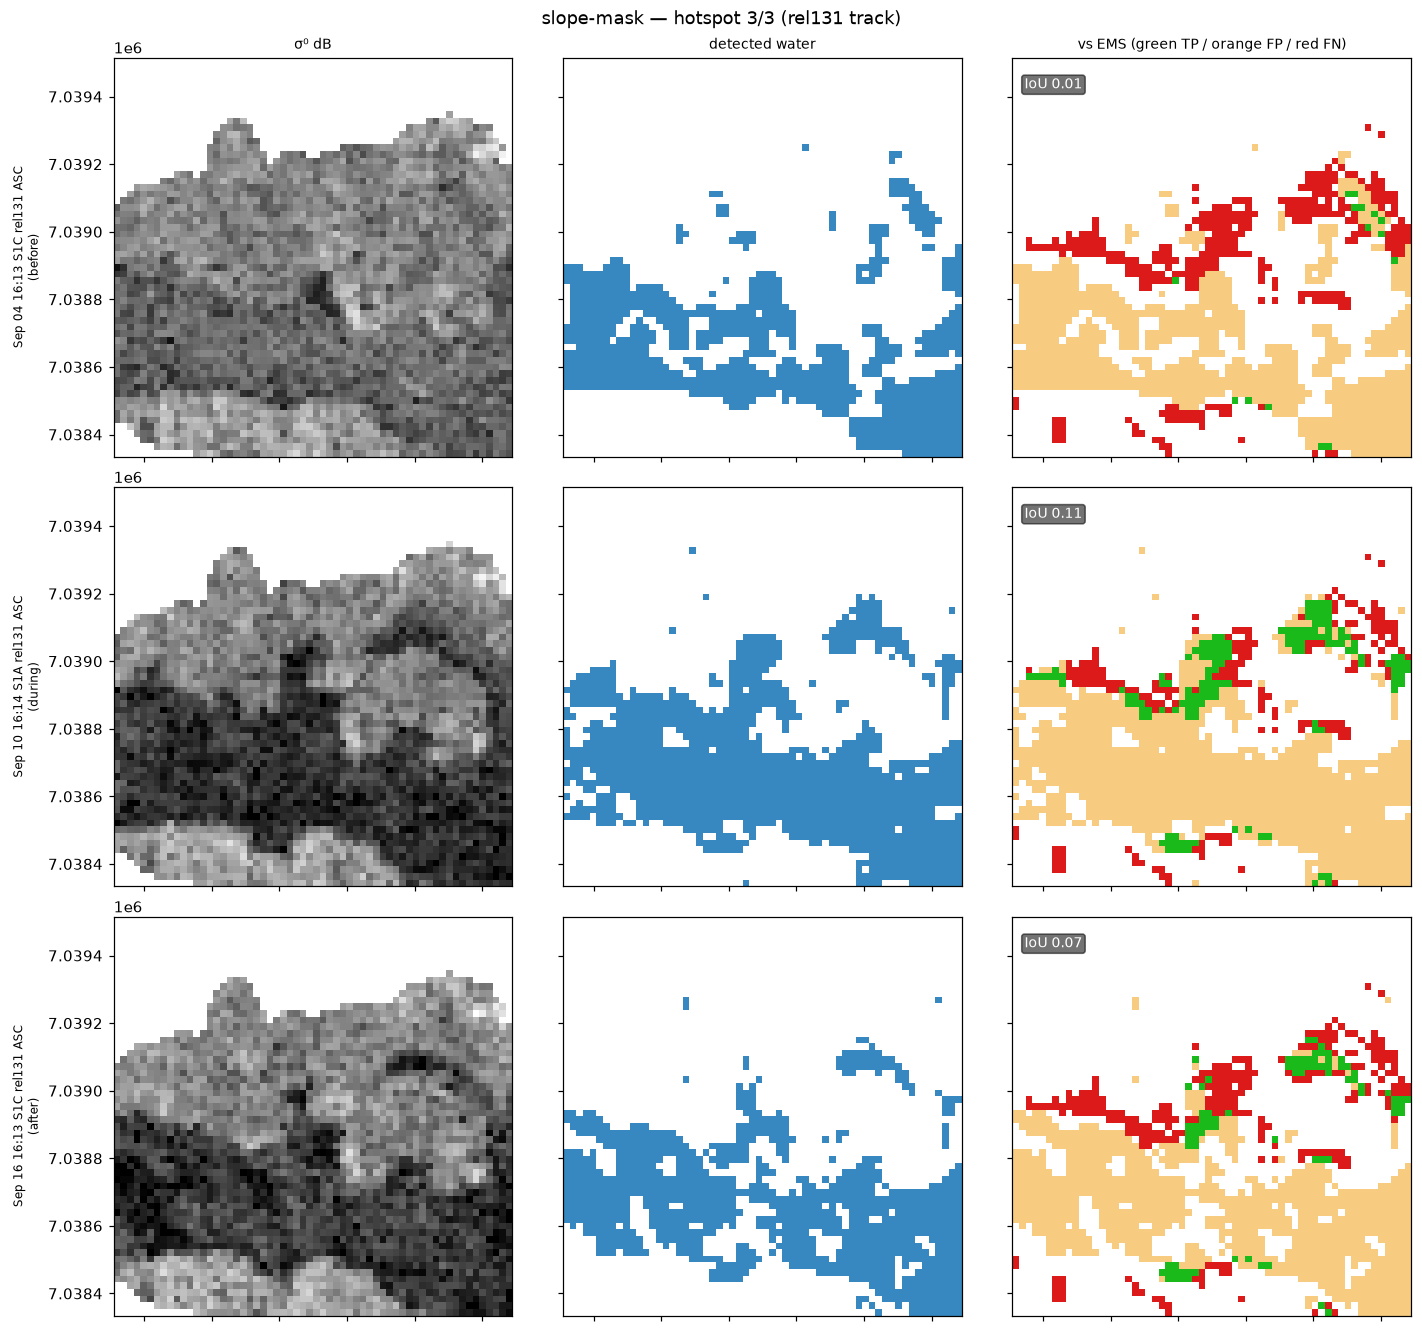

In [ ]:
dem_da = rioxarray.open_rasterio(dem_path).squeeze("band", drop=True)
assert dem_da.shape == scenes[keys[0]]["da"].shape, "DEM grid doesn't match sigma0 grid"
flat_mask = flood.slope_deg(dem_da) < 5.0
print(f"flat-terrain (<5°) fraction of AOI: {float((flat_mask & aoi_mask).sum() / aoi_mask.sum()):.2f}")

def detect_slope(kk):
    mask, thr, note = detect_despeckle(kk)
    return mask & flat_mask, thr, note + " + slope<5°"

scores_slope, dets_slope = evaluate_and_plot("slope-mask", detect_slope)

### 3. Adaptive local threshold

The baseline picks one brightness cutoff for the *whole* scene. But the AOI spans
different land cover (fields, forest, riverbank), so the "normal, dry" backscatter
level genuinely differs place to place — one global number is either too strict
somewhere or too loose elsewhere. This computes a locally-varying threshold instead:
a pixel counts as water if it's darker than *its own neighbourhood's* average, not
the whole scene's.

=== adaptive ===


,scene,method,thr_dB,vs,offset_h,IoU,F1,IoU_union,pred_km2,ems_km2
0,Sep 03 05:06 S1A rel22 DESC,adaptive single-image,-1.6,FEP (S1 Sept 10 16:14),179.1,0.012,0.023,0.016,5.3,1.4
1,Sep 04 16:13 S1C rel131 ASC,adaptive single-image,-1.4,FEP (S1 Sept 10 16:14),144.0,0.005,0.011,0.015,5.5,1.4
2,Sep 09 05:05 S1C rel22 DESC,adaptive log-ratio vs Sep 03,-0.3,FEP (S1 Sept 10 16:14),35.1,0.039,0.075,0.045,4.5,1.4
3,Sep 10 16:14 S1A rel131 ASC,adaptive log-ratio vs Sep 04,-0.2,FEP (S1 Sept 10 16:14),0.0,0.035,0.068,0.050,6.4,1.4
4,Sep 15 05:06 S1A rel22 DESC,adaptive log-ratio vs Sep 03,-0.2,MONIT02 (S1 Sept 15 05:06),0.0,0.022,0.042,0.034,3.3,0.8
5,Sep 16 16:13 S1C rel131 ASC,adaptive log-ratio vs Sep 04,-0.3,MONIT02 (S1 Sept 15 05:06),35.1,0.014,0.028,0.021,5.6,0.8
6,Sep 21 05:05 S1C rel22 DESC,adaptive log-ratio vs Sep 03,-0.3,MONIT02 (S1 Sept 15 05:06),144.0,0.006,0.012,0.016,5.4,0.8


adaptive hotspot 1/3: ~1.2x1.2 km window, 223 true-positive px inside
adaptive hotspot 2/3: ~1.2x1.2 km window, 143 true-positive px inside
adaptive hotspot 3/3: ~1.2x1.2 km window, 78 true-positive px inside


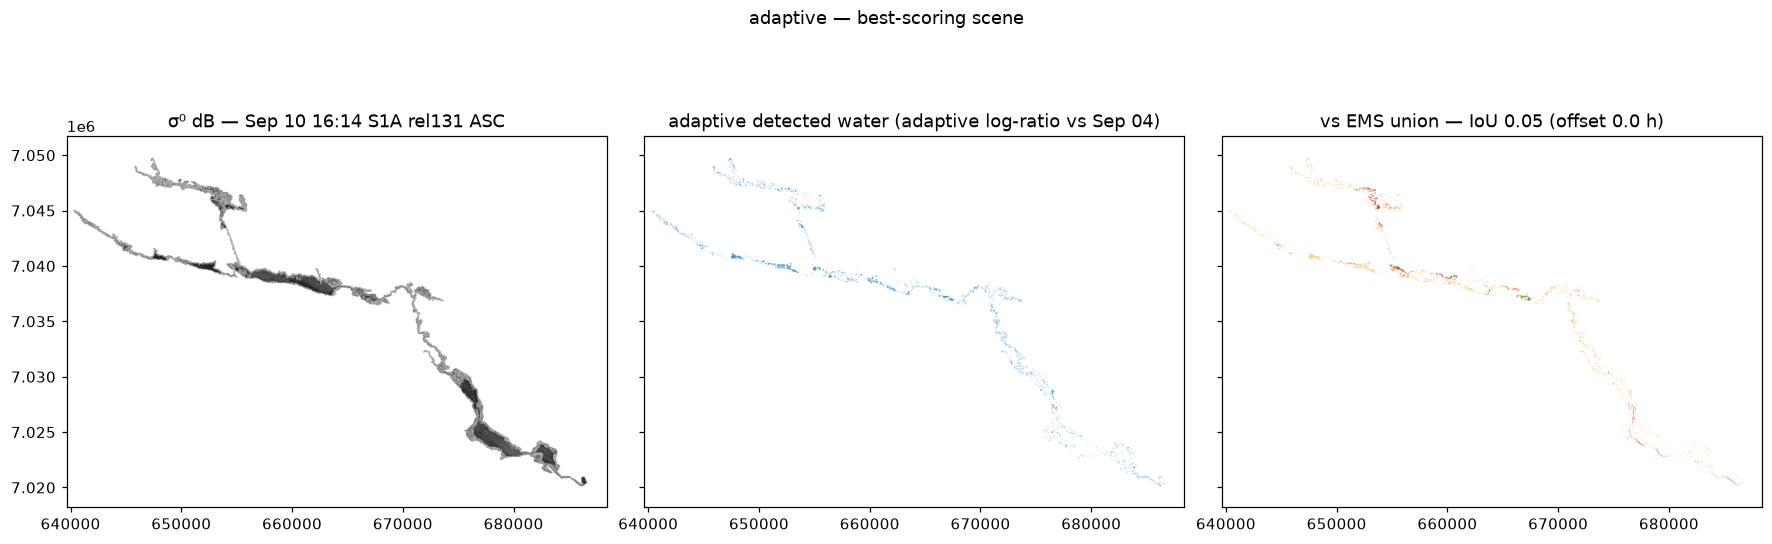

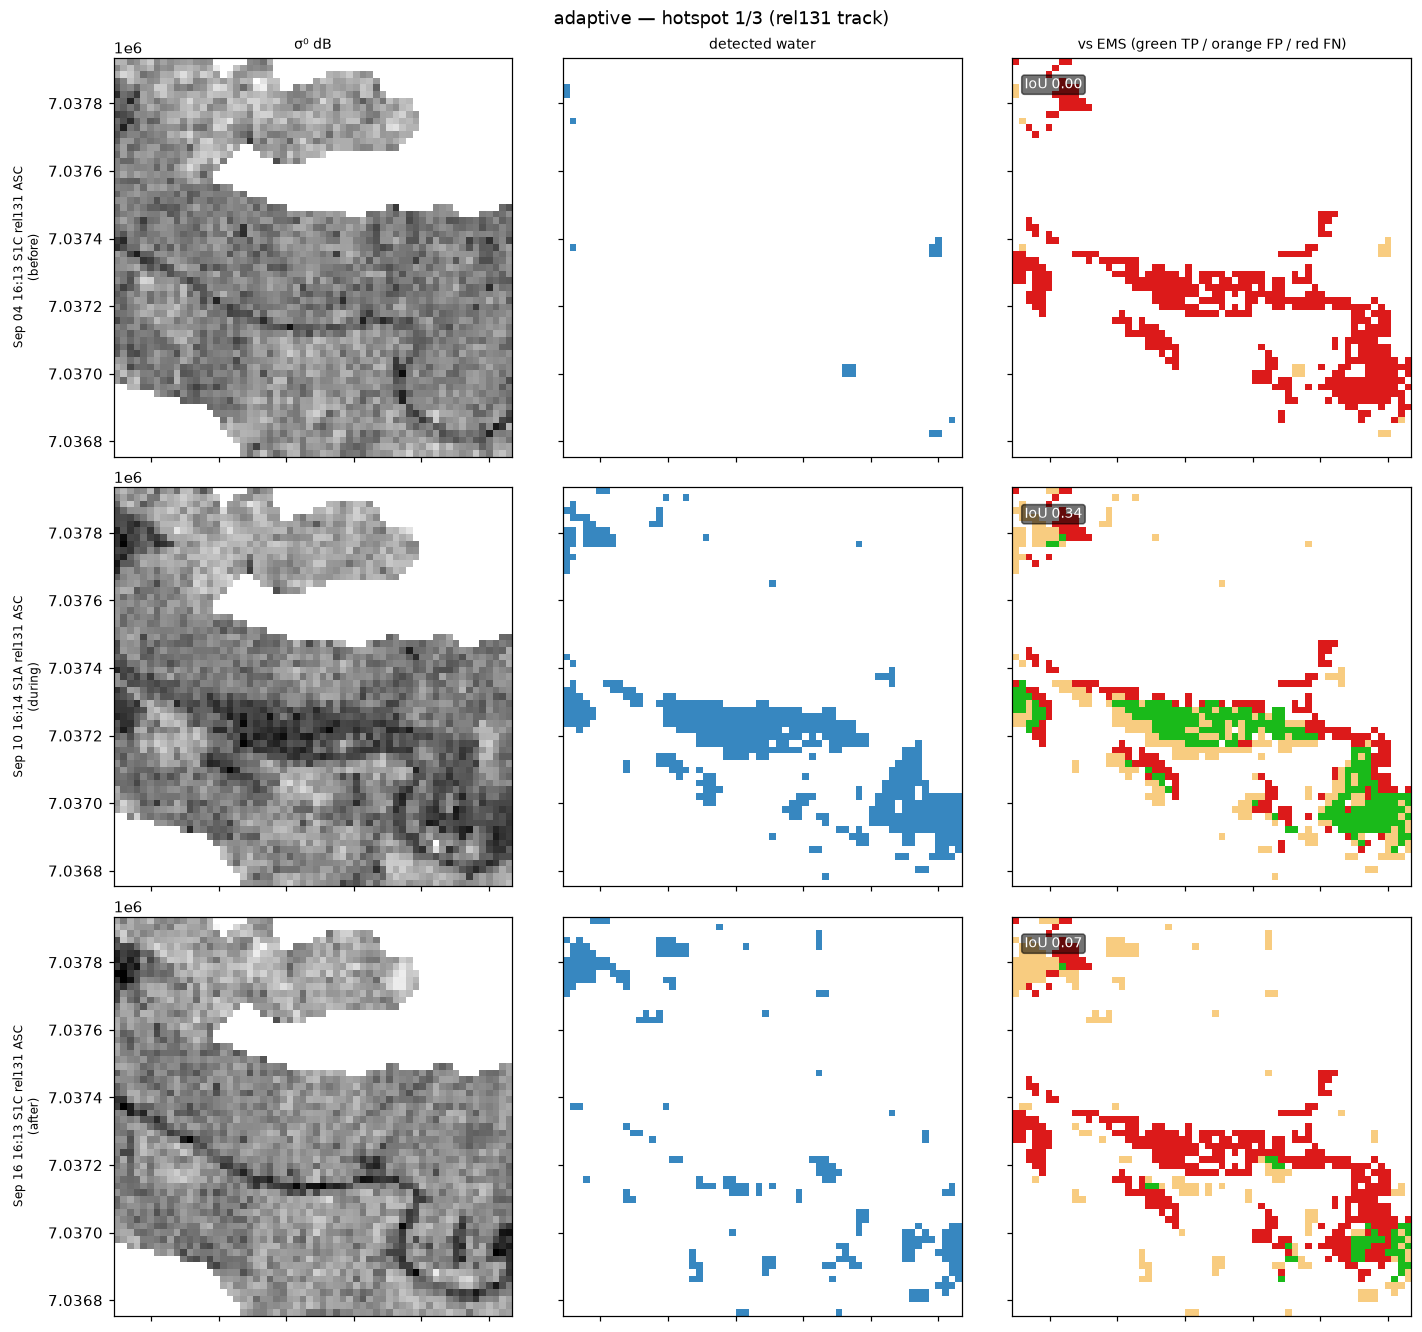

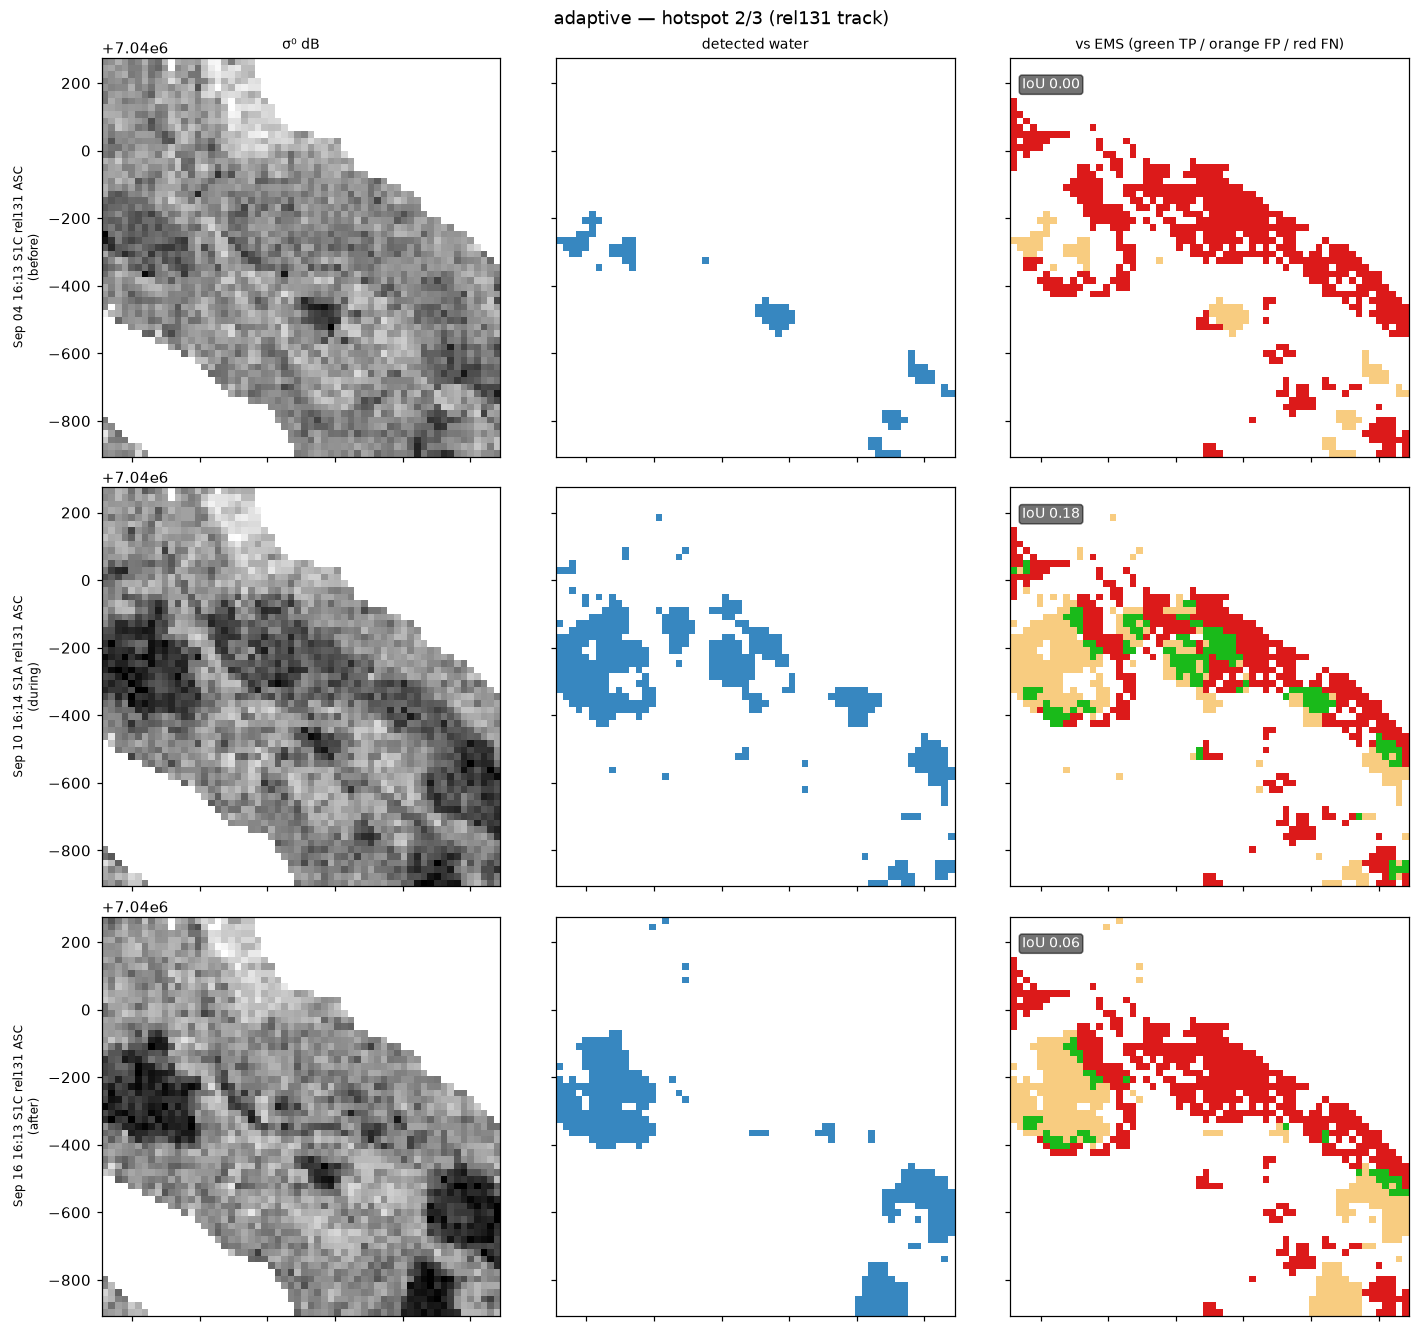

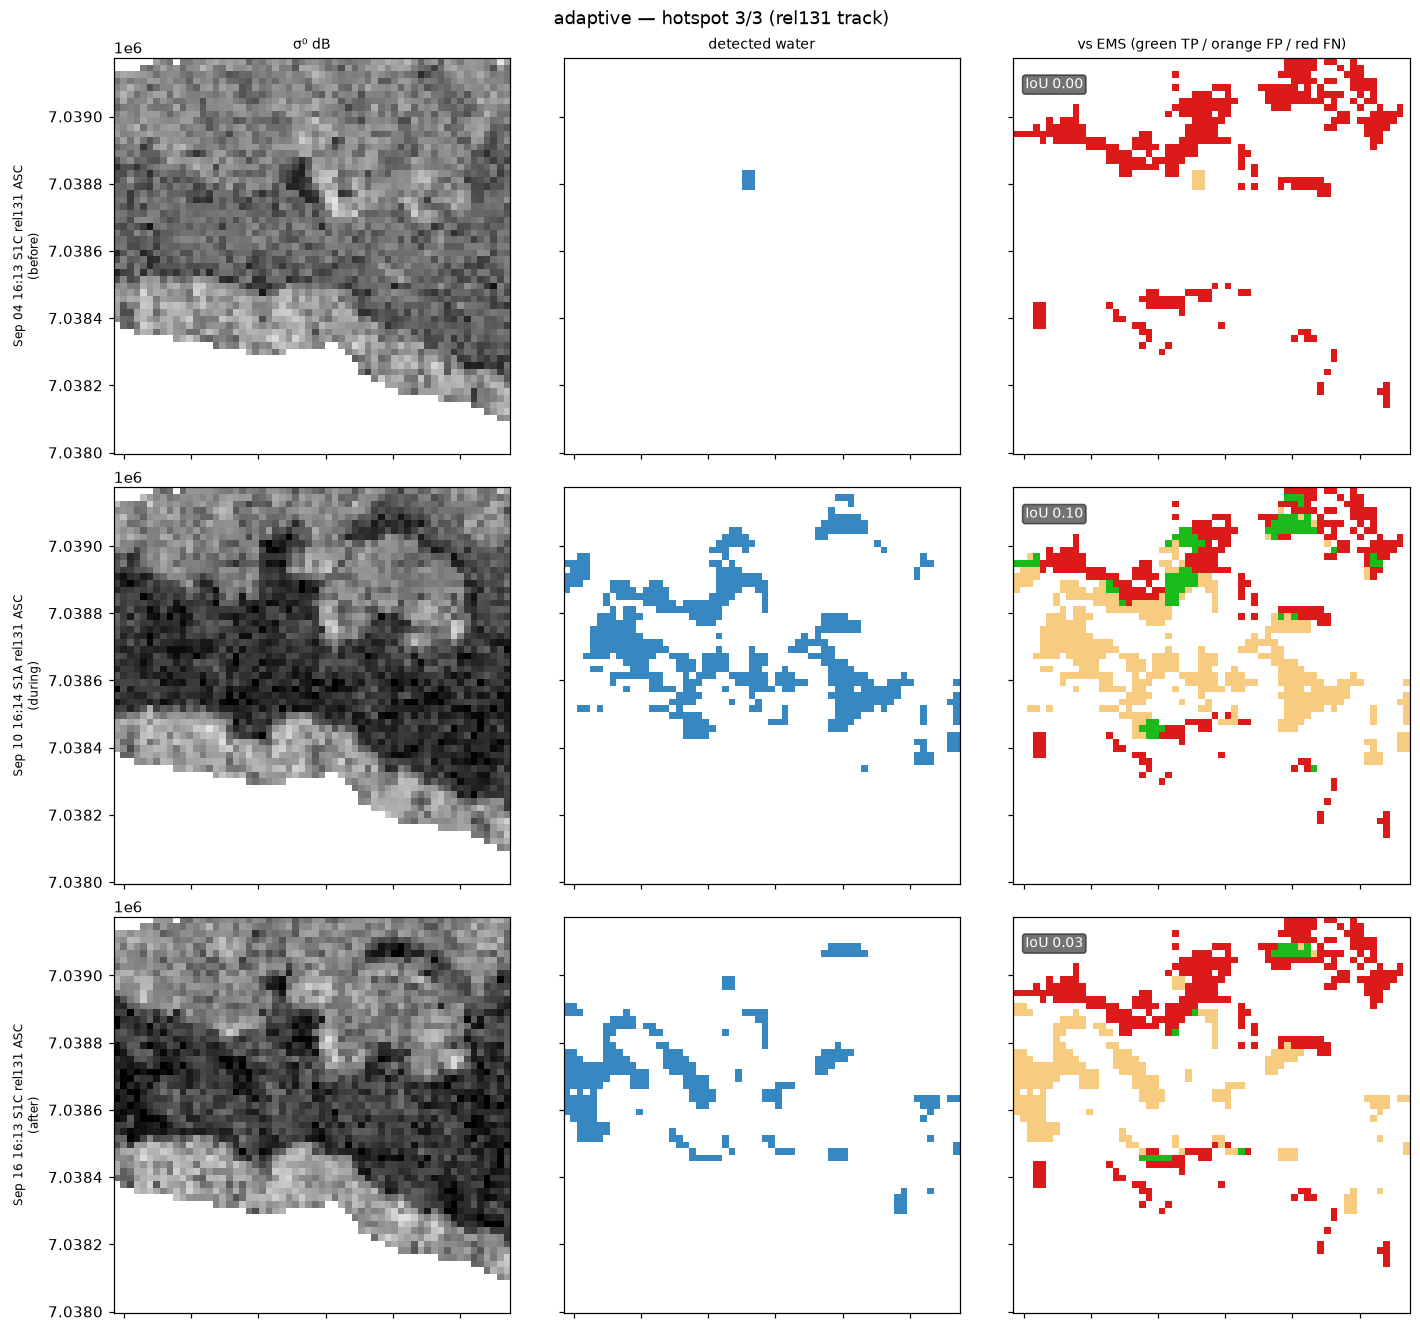

In [ ]:
def detect_adaptive(kk):
    meta = scenes[kk]["meta"]
    db = flood.despeckle(flood.to_db(scenes[kk]["da"]).where(aoi_mask))
    ref = same_track_reference(meta, prods)
    if ref is not None:
        ref_da = grd.gtc_sigma0(ref, "VV", dem_path,
                                GTC_DIR / f"{ref.platform}_{ref.relative_orbit:03d}_{ref.start:%Y%m%d}_VV_sigma0.tif",
                                crop_bbox=BBOX)
        ref_db = flood.despeckle(flood.to_db(ref_da).where(aoi_mask))
        signal = db - ref_db
        note = f"adaptive log-ratio vs {ref.start:%b %d}"
    else:
        signal = db
        note = "adaptive single-image"
    mask, thr = flood.water_mask_adaptive(signal, block=100, k=2.0)
    return mask, thr, note

scores_adaptive, dets_adaptive = evaluate_and_plot("adaptive", detect_adaptive)

## Comparing all four methods

Same scenes, same EMS labels, four different detectors. Stacked into one table and
saved so future runs (or future techniques) have something concrete to compare
against.

              IoU     F1  IoU_union
technique                          
baseline    0.030  0.057      0.043
despeckle   0.017  0.033      0.023
slope-mask  0.015  0.030      0.020
adaptive    0.019  0.037      0.028
wrote /Users/jesper/Documents/Code/raw-sar-monitoring/docs/flood_method_comparison.csv


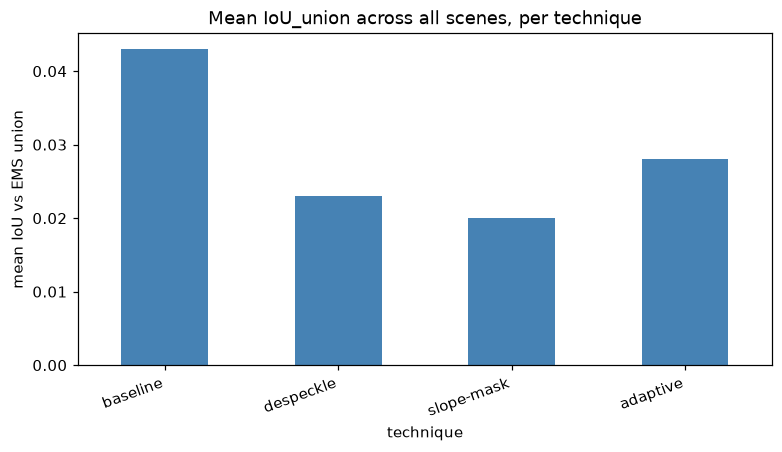

In [ ]:
all_scores = pd.concat([
    scores.assign(technique="baseline"),
    scores_despeckle.assign(technique="despeckle"),
    scores_slope.assign(technique="slope-mask"),
    scores_adaptive.assign(technique="adaptive"),
], ignore_index=True)
summary = all_scores.groupby("technique")[["IoU", "F1", "IoU_union"]].mean().round(3)
summary = summary.reindex(["baseline", "despeckle", "slope-mask", "adaptive"])
print(summary)

out_csv = ROOT / "docs/flood_method_comparison.csv"
all_scores.to_csv(out_csv, index=False)
print("wrote", out_csv)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
summary["IoU_union"].plot.bar(ax=ax, color="steelblue")
ax.set_ylabel("mean IoU vs EMS union")
ax.set_title("Mean IoU_union across all scenes, per technique")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
None

## Takeaways — did the smarter techniques actually help?

Read the summary table above plainly, the same way the baseline's own Takeaways did:
if a technique's mean IoU_union isn't meaningfully above the baseline row, that's a
real result worth keeping, not a failure to hide — a small AOI with tiny, thin flood
polygons (this valley: 2.6 km² union) is a genuinely hard target for any
threshold-based method, and knowing *which* refinement helps (or doesn't) is more
useful than assuming despeckling/slope-masking/adaptive thresholds are automatically
better. `docs/flood_method_comparison.csv` has every scene × technique combination for
follow-up analysis.